# 09 — Model Evaluation

## Purpose

This notebook provides the formal evaluation of the selected Random Forest
model for poultry disease outbreak-count forecasting.

The evaluation focuses on chronological, out-of-sample performance rather than
training-set performance.

The selected model was identified in Notebook 08 using rolling-origin temporal
validation. This notebook evaluates its predictive performance, error behaviour,
temporal stability, and deployment implications.

### Evaluation objectives

1. Load the final saved model and associated metadata.
2. Reconstruct the evaluation data and chronological validation folds.
3. Generate out-of-sample predictions for each validation period.
4. Calculate MAE, RMSE, and Median Absolute Error.
5. Compare performance across chronological periods.
6. Analyse prediction errors and large deviations.
7. Assess temporal stability and potential model drift.
8. Document the model's strengths, limitations, and deployment implications.

> Training-set metrics are not treated as the primary measure of model
> performance because they are optimistic. The main performance evidence
> comes from chronological out-of-sample validation.

In [1]:
# ==============================================================
# MODEL EVALUATION — IMPORTS
# ==============================================================
# This cell imports the libraries required for evaluating the
# selected Random Forest model.
# ==============================================================

import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
)

print("=" * 70)
print("MODEL EVALUATION — INITIALISATION")
print("=" * 70)

print("\nRequired libraries imported successfully.")

MODEL EVALUATION — INITIALISATION

Required libraries imported successfully.


In [4]:
# ==============================================================
# INSPECT LOADED MODEL METADATA
# ==============================================================
# The metadata file was created in Notebook 08.
# Rather than assuming specific JSON key names, we inspect the
# available metadata fields first.
# ==============================================================

print("\nAvailable metadata fields:")

for key, value in evaluation_metadata.items():
    print(f"  {key}: {value}")

print("\n" + "=" * 70)
print("ARTEFACT LOADING PASSED")
print("=" * 70)


Available metadata fields:
  model_name: Random Forest
  model_type: RandomForestRegressor
  model_version: 1.0.0
  target_column: target_outbreak_count
  n_training_records: 445
  n_features: 27
  features: ['year', 'semester_order', 'is_first_semester', 'is_second_semester', 'semester_sin', 'semester_cos', 'years_since_2019', 'year_sin', 'year_cos', 'has_adm1', 'is_country_level', 'disease_code', 'previous_semester_outbreak_count', 'two_semesters_prior_outbreak_count', 'outbreak_history_mean_3', 'outbreak_history_max_3', 'climate_available', 'temperature_missing', 'dewpoint_missing', 'precipitation_missing', 'wind_missing', 'climate_variable_count', 'climate_complete', 'temperature_c', 'dewpoint_c', 'semester_total_precipitation_mm', 'semester_mean_wind_component_magnitude_ms']
  training_period: {'start_period': 4041, 'end_period': 4052}
  validation: {'method': 'rolling_origin_temporal_validation', 'folds': 8, 'mean_fold_mae': 6.533, 'std_fold_mae': 1.661, 'mean_fold_rmse': 11.603

In [5]:
# Load the saved Random Forest pipeline.
evaluation_model = joblib.load(model_path)

# Load model metadata.
with open(metadata_path, "r", encoding="utf-8") as file:
    evaluation_metadata = json.load(file)

# Load the production feature schema.
with open(schema_path, "r", encoding="utf-8") as file:
    production_schema = json.load(file)

print("\nModel artefacts loaded successfully.")

# ==============================================================
# INSPECT LOADED MODEL METADATA
# ==============================================================
# The metadata file was created in Notebook 08.
# Rather than assuming specific JSON key names, we inspect the
# available metadata fields first.
# ==============================================================

print("\nAvailable metadata fields:")

for key, value in evaluation_metadata.items():
    print(f"  {key}: {value}")

print("\n" + "=" * 70)
print("ARTEFACT LOADING PASSED")
print("=" * 70)


Model artefacts loaded successfully.

Available metadata fields:
  model_name: Random Forest
  model_type: RandomForestRegressor
  model_version: 1.0.0
  target_column: target_outbreak_count
  n_training_records: 445
  n_features: 27
  features: ['year', 'semester_order', 'is_first_semester', 'is_second_semester', 'semester_sin', 'semester_cos', 'years_since_2019', 'year_sin', 'year_cos', 'has_adm1', 'is_country_level', 'disease_code', 'previous_semester_outbreak_count', 'two_semesters_prior_outbreak_count', 'outbreak_history_mean_3', 'outbreak_history_max_3', 'climate_available', 'temperature_missing', 'dewpoint_missing', 'precipitation_missing', 'wind_missing', 'climate_variable_count', 'climate_complete', 'temperature_c', 'dewpoint_c', 'semester_total_precipitation_mm', 'semester_mean_wind_component_magnitude_ms']
  training_period: {'start_period': 4041, 'end_period': 4052}
  validation: {'method': 'rolling_origin_temporal_validation', 'folds': 8, 'mean_fold_mae': 6.533, 'std_fold

## 2. Evaluation Dataset

The final Random Forest model was trained on 445 eligible historical
observations using 27 predictor variables.

For formal evaluation, we will reconstruct the modelling dataset used during
the temporal validation process.

The evaluation will preserve the chronological structure of the data and will
not use random train/test splitting.

This ensures that future observations are never used to evaluate predictions
for earlier periods.

In [6]:
# ==============================================================
# LOAD MODELLING DATA FOR EVALUATION
# ==============================================================
# This cell loads the project's processed modelling dataset.
#
# We first inspect the available project files so that we use
# the correct existing data source rather than creating a new
# dataset or guessing a filename.
# ==============================================================

# Display the project root being used.
print(f"Project root: {project_root}")

# Define the directories where processed data is expected.
data_directory = project_root / "data"
processed_directory = data_directory / "processed"

print("\nChecking data directories:")
print(f"Data directory exists:       {data_directory.exists()}")
print(f"Processed directory exists:  {processed_directory.exists()}")

# List files in the processed-data directory.
if processed_directory.exists():
    processed_files = sorted(processed_directory.iterdir())

    print("\nFiles in data/processed:")
    
    if processed_files:
        for file_path in processed_files:
            print(f"  - {file_path.name}")
    else:
        print("  No files found.")
else:
    raise FileNotFoundError(
        f"Processed data directory not found: {processed_directory}"
    )

Project root: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria

Checking data directories:
Data directory exists:       True
Processed directory exists:  True

Files in data/processed:
  - README.md
  - wahis_administrative_boundary_lookup.csv
  - wahis_analytical_table.csv
  - wahis_climate_integrated.csv
  - wahis_modelling_features.csv
  - wahis_quantitative_cleaned.csv


In [7]:
# ==============================================================
# LOAD MODELLING FEATURES
# ==============================================================
# The file "wahis_modelling_features.csv" contains the processed
# features prepared for machine-learning modelling.
#
# We use this dataset as the starting point for reconstructing
# the evaluation data used by the final Random Forest model.
# ==============================================================

modelling_features_path = (
    processed_directory / "wahis_modelling_features.csv"
)

# Load the modelling features.
modelling_features_df = pd.read_csv(modelling_features_path)

print("=" * 70)
print("MODELLING FEATURES LOADED")
print("=" * 70)

print(f"\nFile: {modelling_features_path}")
print(f"Rows: {modelling_features_df.shape[0]}")
print(f"Columns: {modelling_features_df.shape[1]}")

print("\nFirst five rows:")
display(modelling_features_df.head())

print("\nColumn names:")
print(modelling_features_df.columns.tolist())

MODELLING FEATURES LOADED

File: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\data\processed\wahis_modelling_features.csv
Rows: 1180
Columns: 38

First five rows:


,analytical_record_id,year,semester,administrative_division,validated_boundary_name,geographic_level,disease,new_outbreaks,outbreak_count_observed,outbreak_observation_status,...,temperature_missing,dewpoint_missing,precipitation_missing,wind_missing,climate_variable_count,climate_complete,temperature_c,dewpoint_c,semester_total_precipitation_mm,semester_mean_wind_component_magnitude_ms
0,715,2023,Jan-Jun 2023,Abia,Abia,ADM1,Avian infectious bronchitis,NaN,False,Unavailable,...,0,0,0,0,4,1,27.376571,21.949750,410.424905,1.127322
1,375,2021,Jul-Dec 2021,Abia,Abia,ADM1,Fowl typhoid,7.0,True,Observed,...,0,0,0,0,4,1,25.498136,22.369064,1417.637608,0.969542
2,376,2021,Jul-Dec 2021,Abia,Abia,ADM1,Fowl typhoid,NaN,False,Unavailable,...,0,0,0,0,4,1,25.498136,22.369064,1417.637608,0.969542
3,992,2025,Jan-Jun 2025,Abia,Abia,ADM1,Fowl typhoid,1.0,True,Observed,...,0,0,0,0,4,1,27.711400,22.709478,809.382484,1.216022
4,993,2025,Jan-Jun 2025,Abia,Abia,ADM1,Fowl typhoid,NaN,False,Unavailable,...,0,0,0,0,4,1,27.711400,22.709478,809.382484,1.216022



Column names:
['analytical_record_id', 'year', 'semester', 'administrative_division', 'validated_boundary_name', 'geographic_level', 'disease', 'new_outbreaks', 'outbreak_count_observed', 'outbreak_observation_status', 'semester_order', 'is_first_semester', 'is_second_semester', 'semester_sin', 'semester_cos', 'years_since_2019', 'year_sin', 'year_cos', 'has_adm1', 'is_country_level', 'disease_code', 'disease_frequency', 'adm1_disease_record_count', 'previous_semester_outbreak_count', 'two_semesters_prior_outbreak_count', 'outbreak_history_mean_3', 'outbreak_history_max_3', 'climate_available', 'temperature_missing', 'dewpoint_missing', 'precipitation_missing', 'wind_missing', 'climate_variable_count', 'climate_complete', 'temperature_c', 'dewpoint_c', 'semester_total_precipitation_mm', 'semester_mean_wind_component_magnitude_ms']


In [9]:
# ==============================================================
# LOCATE THE TARGET VARIABLE
# ==============================================================
# The modelling-features CSV contains the predictor variables,
# but the target variable is not present in that file.
#
# Before reconstructing the evaluation dataset, this cell checks
# all processed CSV files and identifies where the outbreak target
# and relevant temporal columns are stored.
# ==============================================================

print("=" * 70)
print("SEARCHING PROCESSED DATA FOR EVALUATION TARGET")
print("=" * 70)

# Columns we are specifically looking for.
target_name = evaluation_metadata["target_column"]

search_columns = [
    target_name,
    "outbreak_count",
    "outbreaks",
    "year",
    "semester_order",
    "temporal_period",
]

# Inspect every processed CSV file.
for csv_path in sorted(processed_directory.glob("*.csv")):

    temp_df = pd.read_csv(csv_path, nrows=5)

    matching_columns = [
        column
        for column in search_columns
        if column in temp_df.columns
    ]

    print(f"\nFile: {csv_path.name}")
    print(f"Columns: {len(temp_df.columns)}")

    if matching_columns:
        print("Relevant columns found:")
        for column in matching_columns:
            print(f"  - {column}")
    else:
        print("Relevant target/temporal columns: none")

print("\n" + "=" * 70)
print("TARGET LOCATION CHECK COMPLETE")
print("=" * 70)

SEARCHING PROCESSED DATA FOR EVALUATION TARGET

File: wahis_administrative_boundary_lookup.csv
Columns: 7
Relevant target/temporal columns: none

File: wahis_analytical_table.csv
Columns: 22
Relevant columns found:
  - year

File: wahis_climate_integrated.csv
Columns: 39
Relevant columns found:
  - year

File: wahis_modelling_features.csv
Columns: 38
Relevant columns found:
  - year
  - semester_order

File: wahis_quantitative_cleaned.csv
Columns: 19
Relevant columns found:
  - year

TARGET LOCATION CHECK COMPLETE


## 3. Load the Frozen Evaluation Dataset

The final modelling dataset was exported from Notebook 08 after model
development and final model selection.

The frozen dataset contains the exact 445 eligible observations used by the
final Random Forest model, including the 27 predictor variables and the target
variable.

The corresponding temporal-period values are also loaded so that the
chronological validation structure can be reproduced exactly.

Using this frozen dataset prevents accidental differences between the data used
for model development and the data used for formal evaluation.

In [11]:
# ==============================================================
# LOAD FROZEN EVALUATION DATASET
# ==============================================================
# This cell loads the exact evaluation dataset created in
# Notebook 08.
#
# It contains:
#   - 445 eligible historical observations
#   - 27 predictor variables
#   - 1 target variable
#
# The temporal-period file preserves the chronological information
# required for reproducing the rolling-origin validation.
# ==============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# --------------------------------------------------------------
# 1. Define the project root
# --------------------------------------------------------------
# Notebook 09 is located inside the "notebooks" directory,
# therefore its parent directory is the project root.
# --------------------------------------------------------------

project_root = Path.cwd().parent

print(f"Project root: {project_root}")

# --------------------------------------------------------------
# 2. Define the evaluation artefact paths
# --------------------------------------------------------------

evaluation_directory = (
    project_root / "artifacts" / "evaluation"
)

evaluation_dataset_path = (
    evaluation_directory
    / "model_evaluation_dataset.csv"
)

temporal_values_path = (
    evaluation_directory
    / "temporal_period_values.csv"
)

# --------------------------------------------------------------
# 3. Check that the required files exist
# --------------------------------------------------------------

print("\nChecking evaluation artefacts:")

print(
    f"Evaluation dataset exists: "
    f"{evaluation_dataset_path.exists()}"
)

print(
    f"Temporal values file exists: "
    f"{temporal_values_path.exists()}"
)

if not evaluation_dataset_path.exists():
    raise FileNotFoundError(
        f"Evaluation dataset not found: {evaluation_dataset_path}"
    )

if not temporal_values_path.exists():
    raise FileNotFoundError(
        f"Temporal values file not found: {temporal_values_path}"
    )

# --------------------------------------------------------------
# 4. Load the frozen evaluation dataset
# --------------------------------------------------------------

evaluation_df = pd.read_csv(
    evaluation_dataset_path
)

# Load the temporal period values.
evaluation_temporal_values = pd.read_csv(
    temporal_values_path
)["temporal_period"].to_numpy()

# --------------------------------------------------------------
# 5. Display basic information
# --------------------------------------------------------------

print("\n" + "=" * 70)
print("FROZEN EVALUATION DATASET LOADED")
print("=" * 70)

print(f"\nDataset shape: {evaluation_df.shape}")
print(
    f"Temporal period records: "
    f"{len(evaluation_temporal_values)}"
)

print("\nDataset columns:")
for i, column in enumerate(evaluation_df.columns, start=1):
    print(f"{i:2d}. {column}")

# --------------------------------------------------------------
# 6. Validate the expected structure
# --------------------------------------------------------------

expected_features = evaluation_metadata["features"]
expected_target = evaluation_metadata["target_column"]

expected_columns = (
    expected_features + [expected_target]
)

columns_match = (
    evaluation_df.columns.tolist()
    == expected_columns
)

row_count_valid = (
    len(evaluation_df) == 445
)

column_count_valid = (
    evaluation_df.shape[1] == 28
)

temporal_alignment_valid = (
    len(evaluation_temporal_values)
    == len(evaluation_df)
)

print("\nValidation:")
print(f"445 observations:              {row_count_valid}")
print(f"28 columns:                    {column_count_valid}")
print(f"Feature/target order matches:  {columns_match}")
print(
    f"Temporal records aligned:      "
    f"{temporal_alignment_valid}"
)

# --------------------------------------------------------------
# 7. Stop if the structure is not correct
# --------------------------------------------------------------

if not (
    row_count_valid
    and column_count_valid
    and columns_match
    and temporal_alignment_valid
):
    raise ValueError(
        "Frozen evaluation dataset validation failed."
    )

print("\n" + "=" * 70)
print("EVALUATION DATASET VALIDATION: PASSED")
print("=" * 70)

Project root: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria

Checking evaluation artefacts:
Evaluation dataset exists: True
Temporal values file exists: True

FROZEN EVALUATION DATASET LOADED

Dataset shape: (445, 28)
Temporal period records: 445

Dataset columns:
 1. year
 2. semester_order
 3. is_first_semester
 4. is_second_semester
 5. semester_sin
 6. semester_cos
 7. years_since_2019
 8. year_sin
 9. year_cos
10. has_adm1
11. is_country_level
12. disease_code
13. previous_semester_outbreak_count
14. two_semesters_prior_outbreak_count
15. outbreak_history_mean_3
16. outbreak_history_max_3
17. climate_available
18. temperature_missing
19. dewpoint_missing
20. precipitation_missing
21. wind_missing
22. climate_variable_count
23. climate_complete
24. temperature_c
25. dewpoint_c
26. semester_total_precipitation_mm
27. semester_mean_wind_component_magnitude_ms
28. target_outbreak_count

Validation:
445 observations:              True
28 columns:                    

## 4.1 Reconstruct the Random Forest Evaluation Pipeline

The saved production model was trained on all eligible historical observations.
For formal out-of-sample evaluation, a fresh Random Forest pipeline is
reconstructed with the same preprocessing and model configuration used during
development.

A separate clone of this pipeline is fitted within each chronological
validation fold.

In [13]:
# ============================================================
# 4.1 RECONSTRUCT RANDOM FOREST EVALUATION PIPELINE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

# Numeric features used by the model
numeric_features = evaluation_metadata["features"]

# Median imputation for numeric variables
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features)
    ],
    remainder="drop"
)

# Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Complete modelling pipeline
random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", random_forest_model)
    ]
)

print("=" * 70)
print("RANDOM FOREST EVALUATION PIPELINE RECONSTRUCTED")
print("=" * 70)

print("Model:", type(random_forest_model).__name__)
print("Number of estimators:", random_forest_model.n_estimators)
print("Random state:", random_forest_model.random_state)
print("Number of features:", len(numeric_features))
print("Pipeline ready:", True)

RANDOM FOREST EVALUATION PIPELINE RECONSTRUCTED
Model: RandomForestRegressor
Number of estimators: 300
Random state: 42
Number of features: 27
Pipeline ready: True


In [15]:
# ============================================================
# DIAGNOSTIC — INSPECT ACTUAL TEMPORAL PERIOD VALUES
# ============================================================

temporal_check = pd.DataFrame({
    "temporal_period": temporal_values
})

temporal_summary = (
    temporal_check
    .groupby("temporal_period")
    .size()
    .reset_index(name="record_count")
    .sort_values("temporal_period")
    .reset_index(drop=True)
)

print("=" * 70)
print("ACTUAL TEMPORAL PERIOD DISTRIBUTION")
print("=" * 70)

print("\nNumber of unique temporal periods:",
      temporal_summary["temporal_period"].nunique())

display(temporal_summary)

ACTUAL TEMPORAL PERIOD DISTRIBUTION

Number of unique temporal periods: 12


,temporal_period,record_count
0,4041,12
1,4042,19
2,4043,45
3,4044,67
4,4045,45
5,4046,49
6,4047,22
7,4048,22
8,4049,35
9,4050,33


In [17]:
# ============================================================
# CONSTRUCT CHRONOLOGICAL ROLLING-ORIGIN FOLDS
# ============================================================

# Convert temporal values to a pandas Series so that
# .isin() can be used safely.
temporal_series = pd.Series(
    temporal_values,
    index=evaluation_df.index,
    name="temporal_period"
)

# Get unique temporal periods in chronological order
unique_periods = (
    temporal_series
    .drop_duplicates()
    .sort_values()
    .tolist()
)

print("=" * 70)
print("CHRONOLOGICAL PERIODS")
print("=" * 70)

for i, period in enumerate(unique_periods, start=1):

    period_count = (
        temporal_series == period
    ).sum()

    print(
        f"Period {i}: {period} -> "
        f"{period_count} observations"
    )


# ------------------------------------------------------------
# Build rolling-origin folds
#
# For each fold:
#   Training = all periods before the validation period
#   Validation = the next unseen period
# ------------------------------------------------------------

rolling_folds = []

for i in range(1, len(unique_periods)):

    validation_period = unique_periods[i]

    training_periods = unique_periods[:i]

    train_mask = temporal_series.isin(
        training_periods
    )

    validation_mask = (
        temporal_series == validation_period
    )

    train_records = train_mask.sum()
    validation_records = validation_mask.sum()

    if train_records > 0 and validation_records > 0:

        rolling_folds.append({
            "fold": len(rolling_folds) + 1,
            "train_period_start": training_periods[0],
            "train_period_end": training_periods[-1],
            "validation_period": validation_period,
            "train_records": train_records,
            "validation_records": validation_records,
            "train_mask": train_mask,
            "validation_mask": validation_mask
        })


# ------------------------------------------------------------
# Display fold structure
# ------------------------------------------------------------

fold_structure = pd.DataFrame([
    {
        "fold": fold["fold"],
        "train_period_start": fold["train_period_start"],
        "train_period_end": fold["train_period_end"],
        "validation_period": fold["validation_period"],
        "train_records": fold["train_records"],
        "validation_records": fold["validation_records"]
    }
    for fold in rolling_folds
])

print("\n" + "=" * 70)
print("ROLLING-ORIGIN FOLD STRUCTURE")
print("=" * 70)

display(fold_structure)

print(
    "\nNumber of rolling-origin folds:",
    len(rolling_folds)
)

CHRONOLOGICAL PERIODS
Period 1: 4041 -> 12 observations
Period 2: 4042 -> 19 observations
Period 3: 4043 -> 45 observations
Period 4: 4044 -> 67 observations
Period 5: 4045 -> 45 observations
Period 6: 4046 -> 49 observations
Period 7: 4047 -> 22 observations
Period 8: 4048 -> 22 observations
Period 9: 4049 -> 35 observations
Period 10: 4050 -> 33 observations
Period 11: 4051 -> 39 observations
Period 12: 4052 -> 57 observations

ROLLING-ORIGIN FOLD STRUCTURE


,fold,train_period_start,train_period_end,validation_period,train_records,validation_records
0,1,4041,4041,4042,12,19
1,2,4041,4042,4043,31,45
2,3,4041,4043,4044,76,67
3,4,4041,4044,4045,143,45
4,5,4041,4045,4046,188,49
5,6,4041,4046,4047,237,22
6,7,4041,4047,4048,259,22
7,8,4041,4048,4049,281,35
8,9,4041,4049,4050,316,33
9,10,4041,4050,4051,349,39



Number of rolling-origin folds: 11


In [19]:
# ============================================================
# SECTION 4 — FINAL ROLLING-ORIGIN OUT-OF-SAMPLE EVALUATION
# ============================================================

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error
)

# ------------------------------------------------------------
# 1. Prepare evaluation data
# ------------------------------------------------------------

X_eval = evaluation_df[
    evaluation_metadata["features"]
].copy()

y_eval = evaluation_df[
    evaluation_metadata["target_column"]
].copy()

# Convert temporal values to a pandas Series
temporal_series = pd.Series(
    temporal_values,
    index=evaluation_df.index,
    name="temporal_period"
)

# ------------------------------------------------------------
# 2. Select the same eight validation periods used
#    during model development in Notebook 08
# ------------------------------------------------------------

# The first four temporal periods provide historical
# training context. Formal evaluation begins at period 4045.

evaluation_periods = [
    4045,  # 2022 Jan-Jun
    4046,  # 2022 Jul-Dec
    4047,  # 2023 Jan-Jun
    4048,  # 2023 Jul-Dec
    4049,  # 2024 Jan-Jun
    4050,  # 2024 Jul-Dec
    4051,  # 2025 Jan-Jun
    4052   # 2025 Jul-Dec
]

# ------------------------------------------------------------
# 3. Run rolling-origin evaluation
# ------------------------------------------------------------

fold_results = []
oos_predictions = []

for fold_number, validation_period in enumerate(
    evaluation_periods,
    start=1
):

    # All periods before the validation period
    # are available for training.
    train_mask = (
        temporal_series < validation_period
    )

    # Only the current future period is used
    # for validation.
    validation_mask = (
        temporal_series == validation_period
    )

    X_train = X_eval.loc[
        train_mask
    ].copy()

    y_train = y_eval.loc[
        train_mask
    ].copy()

    X_validation = X_eval.loc[
        validation_mask
    ].copy()

    y_validation = y_eval.loc[
        validation_mask
    ].copy()

    # --------------------------------------------------------
    # Sanity checks
    # --------------------------------------------------------

    if len(X_train) == 0:
        raise ValueError(
            f"Fold {fold_number}: training set is empty."
        )

    if len(X_validation) == 0:
        raise ValueError(
            f"Fold {fold_number}: validation set is empty."
        )

    # --------------------------------------------------------
    # Create a fresh Random Forest pipeline
    # --------------------------------------------------------

    fold_model = clone(
        random_forest_pipeline
    )

    # Fit ONLY on observations before
    # the validation period.
    fold_model.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------------
    # Generate predictions for unseen observations
    # --------------------------------------------------------

    y_pred = fold_model.predict(
        X_validation
    )

    # --------------------------------------------------------
    # Calculate metrics
    # --------------------------------------------------------

    fold_mae = mean_absolute_error(
        y_validation,
        y_pred
    )

    fold_rmse = np.sqrt(
        mean_squared_error(
            y_validation,
            y_pred
        )
    )

    fold_median_ae = median_absolute_error(
        y_validation,
        y_pred
    )

    # --------------------------------------------------------
    # Store fold-level results
    # --------------------------------------------------------

    fold_results.append({
        "fold": fold_number,
        "validation_period": validation_period,
        "train_records": len(X_train),
        "validation_records": len(X_validation),
        "mae": fold_mae,
        "rmse": fold_rmse,
        "median_absolute_error": fold_median_ae
    })

    # --------------------------------------------------------
    # Store individual out-of-sample predictions
    # --------------------------------------------------------

    fold_prediction_df = pd.DataFrame({
        "fold": fold_number,
        "temporal_period": temporal_series.loc[
            validation_mask
        ].values,
        "actual_outbreak_count": y_validation.values,
        "predicted_outbreak_count": y_pred
    })

    oos_predictions.append(
        fold_prediction_df
    )


# ------------------------------------------------------------
# 4. Combine results
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(
    fold_results
)

oos_predictions_df = pd.concat(
    oos_predictions,
    ignore_index=True
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("=" * 70)
print("FINAL ROLLING-ORIGIN OUT-OF-SAMPLE EVALUATION")
print("=" * 70)

print(
    "\nNumber of validation folds:",
    len(fold_results_df)
)

print(
    "Total out-of-sample predictions:",
    len(oos_predictions_df)
)

print(
    "Expected out-of-sample predictions:",
    302
)

print(
    "Prediction count matches expected:",
    len(oos_predictions_df) == 302
)

print("\nFold-level results:")

display(
    fold_results_df.round(3)
)

FINAL ROLLING-ORIGIN OUT-OF-SAMPLE EVALUATION

Number of validation folds: 8
Total out-of-sample predictions: 302
Expected out-of-sample predictions: 302
Prediction count matches expected: True

Fold-level results:


,fold,validation_period,train_records,validation_records,mae,rmse,median_absolute_error
0,1,4045,143,45,3.947,5.783,2.187
1,2,4046,188,49,4.857,6.810,2.940
2,3,4047,237,22,8.266,12.081,3.927
3,4,4048,259,22,2.733,3.945,1.273
4,5,4049,281,35,4.043,6.022,1.760
5,6,4050,316,33,3.273,4.004,2.967
6,7,4051,349,39,2.655,3.782,1.830
7,8,4052,388,57,2.456,3.448,1.610


In [20]:
# ============================================================
# SECTION 4.1 — VERIFY NOTEBOOK 08 VS NOTEBOOK 09 METRICS
# ============================================================

print("=" * 70)
print("NOTEBOOK 09 EVALUATION SUMMARY")
print("=" * 70)

evaluation_summary = {
    "mean_fold_mae": fold_results_df["mae"].mean(),
    "std_fold_mae": fold_results_df["mae"].std(),
    "mean_fold_rmse": fold_results_df["rmse"].mean(),
    "std_fold_rmse": fold_results_df["rmse"].std(),
    "mean_fold_median_absolute_error": (
        fold_results_df["median_absolute_error"].mean()
    ),
}

for key, value in evaluation_summary.items():
    print(f"{key}: {value:.3f}")

print("\nFold-level MAE:")
print(fold_results_df[["fold", "validation_period", "mae"]].to_string(index=False))

print("\nFold-level RMSE:")
print(fold_results_df[["fold", "validation_period", "rmse"]].to_string(index=False))

NOTEBOOK 09 EVALUATION SUMMARY
mean_fold_mae: 4.029
std_fold_mae: 1.900
mean_fold_rmse: 5.734
std_fold_rmse: 2.847
mean_fold_median_absolute_error: 2.312

Fold-level MAE:
 fold  validation_period      mae
    1               4045 3.947037
    2               4046 4.856599
    3               4047 8.266212
    4               4048 2.732576
    5               4049 4.042667
    6               4050 3.273434
    7               4051 2.654786
    8               4052 2.455673

Fold-level RMSE:
 fold  validation_period      rmse
    1               4045  5.782809
    2               4046  6.809744
    3               4047 12.080804
    4               4048  3.945352
    5               4049  6.022099
    6               4050  4.003866
    7               4051  3.781827
    8               4052  3.447660


In [22]:
# ============================================================
# SECTION 4.2 — VERIFY EVALUATION DATA AND FEATURE VALUES
# ============================================================

print("=" * 70)
print("EVALUATION DATA INTEGRITY CHECK")
print("=" * 70)

# Basic dimensions
print(f"Evaluation dataframe shape: {evaluation_df.shape}")
print(f"Feature columns: {len(evaluation_metadata['features'])}")
print(f"Target column: {evaluation_metadata['target_column']}")

# Feature data types
print("\nFeature dtypes:")
print(
    evaluation_df[evaluation_metadata["features"]]
    .dtypes
    .value_counts()
)

# Target distribution
print("\nTarget summary:")
print(
    evaluation_df[evaluation_metadata["target_column"]]
    .describe()
)

# Missing values
print("\nMissing values in model features:")

missing_features = (
    evaluation_df[evaluation_metadata["features"]]
    .isna()
    .sum()
)

missing_features = missing_features[missing_features > 0]

if len(missing_features) == 0:
    print("No missing feature values.")
else:
    print(missing_features)

# Temporal period distribution
print("\nTemporal period distribution:")

temporal_distribution = (
    pd.Series(temporal_values)
    .value_counts()
    .sort_index()
)

print(temporal_distribution)

# First five feature rows
print("\nFirst 5 rows of model features:")

display(
    evaluation_df[
        evaluation_metadata["features"]
    ].head()
)

# First five target values with temporal periods
print("\nFirst 5 target values and temporal periods:")

target_temporal_check = pd.DataFrame({
    "temporal_period": temporal_values[:5],
    "target_outbreak_count": evaluation_df[
        evaluation_metadata["target_column"]
    ].head().values
})

display(target_temporal_check)

EVALUATION DATA INTEGRITY CHECK
Evaluation dataframe shape: (445, 28)
Feature columns: 27
Target column: target_outbreak_count

Feature dtypes:
int64      15
float64    12
Name: count, dtype: int64

Target summary:
count    445.000000
mean       6.840449
std       12.872353
min        1.000000
25%        1.000000
50%        3.000000
75%        7.000000
max      184.000000
Name: target_outbreak_count, dtype: float64

Missing values in model features:
previous_semester_outbreak_count             135
two_semesters_prior_outbreak_count           198
outbreak_history_mean_3                      105
outbreak_history_max_3                       105
temperature_c                                  1
dewpoint_c                                     1
semester_total_precipitation_mm                1
semester_mean_wind_component_magnitude_ms      1
dtype: int64

Temporal period distribution:
4041    12
4042    19
4043    45
4044    67
4045    45
4046    49
4047    22
4048    22
4049    35
4050    33


,year,semester_order,is_first_semester,is_second_semester,semester_sin,semester_cos,years_since_2019,year_sin,year_cos,has_adm1,...,temperature_missing,dewpoint_missing,precipitation_missing,wind_missing,climate_variable_count,climate_complete,temperature_c,dewpoint_c,semester_total_precipitation_mm,semester_mean_wind_component_magnitude_ms
0,2021,2,0,1,1.224647e-16,-1.0,2,-9.510565e-01,0.309017,1,...,0,0,0,0,4,1,25.498136,22.369064,1417.637608,0.969542
1,2025,1,1,0,0.000000e+00,1.0,6,-2.449294e-16,1.000000,1,...,0,0,0,0,4,1,27.711400,22.709478,809.382484,1.216022
2,2021,1,1,0,0.000000e+00,1.0,2,-9.510565e-01,0.309017,1,...,0,0,0,0,4,1,27.652334,22.147942,599.798555,1.176361
3,2021,2,0,1,1.224647e-16,-1.0,2,-9.510565e-01,0.309017,1,...,0,0,0,0,4,1,25.498136,22.369064,1417.637608,0.969542
4,2022,1,1,0,0.000000e+00,1.0,3,-8.090170e-01,0.587785,1,...,0,0,0,0,4,1,27.335367,21.532264,632.624339,1.061308



First 5 target values and temporal periods:


,temporal_period,target_outbreak_count
0,4041,7.0
1,4041,1.0
2,4041,2.0
3,4041,5.0
4,4041,2.0


## 4.3 Reproduce Notebook 08 Chronological Data Ordering

The formal evaluation must reproduce the data ordering used during the original model-selection experiment.

Notebook 08 sorts the modelling dataset by `temporal_period` before generating rolling-origin splits. Because Random Forest training can depend on the order in which observations are supplied to the estimator, Notebook 09 explicitly reproduces this ordering before fitting each validation-fold model.

This step ensures that the formal evaluation is reproducible with the original model-selection experiment.

In [23]:
# ============================================================
# SECTION 4.3 — REPRODUCE NOTEBOOK 08 DATA ORDERING
# ============================================================

print("=" * 70)
print("REPRODUCING NOTEBOOK 08 CHRONOLOGICAL DATA ORDERING")
print("=" * 70)

# Create the same temporal-period encoding used in Notebook 08.
evaluation_df["temporal_period"] = (
    evaluation_df["year"] * 2
    + (evaluation_df["semester_order"] - 1)
)

# Reproduce Notebook 08's chronological sorting exactly.
evaluation_df = (
    evaluation_df
    .sort_values(["temporal_period"])
    .reset_index(drop=True)
)

# Re-align temporal values with the newly sorted dataframe.
temporal_values = evaluation_df["temporal_period"].to_numpy()

# Confirm chronological ordering.
if not np.all(
    np.diff(temporal_values) >= 0
):
    raise ValueError(
        "Evaluation dataset is not chronologically ordered."
    )

print("\nEvaluation dataset shape:", evaluation_df.shape)

print(
    "First temporal period:",
    temporal_values[0]
)

print(
    "Last temporal period:",
    temporal_values[-1]
)

print("\nTemporal period distribution:")

print(
    pd.Series(temporal_values)
    .value_counts()
    .sort_index()
)

print("\nFirst 10 temporal periods:")
print(temporal_values[:10])

print("\n" + "=" * 70)
print("NOTEBOOK 08 DATA ORDERING REPRODUCED")
print("=" * 70)

REPRODUCING NOTEBOOK 08 CHRONOLOGICAL DATA ORDERING

Evaluation dataset shape: (445, 29)
First temporal period: 4040
Last temporal period: 4051

Temporal period distribution:
4040    12
4041    19
4042    45
4043    67
4044    45
4045    49
4046    22
4047    22
4048    35
4049    33
4050    39
4051    57
Name: count, dtype: int64

First 10 temporal periods:
[4040 4040 4040 4040 4040 4040 4040 4040 4040 4040]

NOTEBOOK 08 DATA ORDERING REPRODUCED


In [25]:
# ============================================================
# FINAL ROLLING-ORIGIN OUT-OF-SAMPLE EVALUATION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error

print("=" * 70)
print("FINAL ROLLING-ORIGIN OUT-OF-SAMPLE EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Restore model feature definitions
# ------------------------------------------------------------

X_columns = evaluation_metadata["features"]
y_column = evaluation_metadata["target_column"]

print(f"Number of features: {len(X_columns)}")
print(f"Target column: {y_column}")

# Confirm all required columns exist
missing_columns = [
    column for column in X_columns + [y_column]
    if column not in evaluation_df.columns
]

if missing_columns:
    raise ValueError(
        "Missing required evaluation columns: "
        + ", ".join(missing_columns)
    )

# ------------------------------------------------------------
# 2. Confirm chronological ordering
# ------------------------------------------------------------

evaluation_df = evaluation_df.sort_values(
    by=["temporal_period"]
).reset_index(drop=True)

print(f"Evaluation records: {len(evaluation_df)}")
print(
    f"Temporal range: "
    f"{evaluation_df['temporal_period'].min()} "
    f"to "
    f"{evaluation_df['temporal_period'].max()}"
)

# ------------------------------------------------------------
# 3. Define the eight formal validation periods
#    These match Notebook 08:
#    minimum training periods = 4
#    test periods = 1
# ------------------------------------------------------------

evaluation_periods = [
    4044,
    4045,
    4046,
    4047,
    4048,
    4049,
    4050,
    4051
]

print("\nFormal validation periods:")
print(evaluation_periods)

# ------------------------------------------------------------
# 4. Rolling-origin evaluation
# ------------------------------------------------------------

fold_results = []
oos_predictions = []

for fold_number, validation_period in enumerate(
    evaluation_periods,
    start=1
):

    # Training data = all periods before validation period
    train_mask = (
        evaluation_df["temporal_period"]
        < validation_period
    )

    # Validation data = current validation period
    validation_mask = (
        evaluation_df["temporal_period"]
        == validation_period
    )

    train_data = evaluation_df.loc[
        train_mask
    ].copy()

    validation_data = evaluation_df.loc[
        validation_mask
    ].copy()

    X_train = train_data[X_columns]
    y_train = train_data[y_column]

    X_validation = validation_data[X_columns]
    y_validation = validation_data[y_column]

    # Clone the original model pipeline
    fold_model = clone(random_forest_pipeline)

    # Fit only on historical training data
    fold_model.fit(
        X_train,
        y_train
    )

    # Predict the future validation period
    y_prediction = fold_model.predict(
        X_validation
    )

    # Calculate out-of-sample metrics
    fold_mae = mean_absolute_error(
        y_validation,
        y_prediction
    )

    fold_rmse = np.sqrt(
        mean_squared_error(
            y_validation,
            y_prediction
        )
    )

    fold_median_ae = median_absolute_error(
        y_validation,
        y_prediction
    )

    # Store fold-level metrics
    fold_results.append({
        "fold": fold_number,
        "validation_period": validation_period,
        "training_records": len(train_data),
        "validation_records": len(validation_data),
        "mae": fold_mae,
        "rmse": fold_rmse,
        "median_absolute_error": fold_median_ae
    })

    # Store predictions for pooled evaluation
    fold_predictions = validation_data[
        ["temporal_period", y_column]
    ].copy()

    fold_predictions["fold"] = fold_number
    fold_predictions["predicted_outbreak_count"] = y_prediction

    oos_predictions.append(
        fold_predictions
    )

# ------------------------------------------------------------
# 5. Create results tables
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(
    fold_results
)

oos_predictions_df = pd.concat(
    oos_predictions,
    ignore_index=True
)

# ------------------------------------------------------------
# 6. Calculate overall fold-level statistics
# ------------------------------------------------------------

mean_fold_mae = fold_results_df["mae"].mean()
std_fold_mae = fold_results_df["mae"].std(ddof=1)

mean_fold_rmse = fold_results_df["rmse"].mean()
std_fold_rmse = fold_results_df["rmse"].std(ddof=1)

mean_fold_median_ae = (
    fold_results_df[
        "median_absolute_error"
    ].mean()
)

# ------------------------------------------------------------
# 7. Calculate pooled out-of-sample metrics
# ------------------------------------------------------------

y_oos = oos_predictions_df[
    y_column
]

y_oos_pred = oos_predictions_df[
    "predicted_outbreak_count"
]

pooled_mae = mean_absolute_error(
    y_oos,
    y_oos_pred
)

pooled_rmse = np.sqrt(
    mean_squared_error(
        y_oos,
        y_oos_pred
    )
)

pooled_median_ae = median_absolute_error(
    y_oos,
    y_oos_pred
)

# ------------------------------------------------------------
# 8. Display fold-level results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FOLD-LEVEL RESULTS")
print("=" * 70)

display(
    fold_results_df.round(3)
)

# ------------------------------------------------------------
# 9. Display overall results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ROLLING-ORIGIN PERFORMANCE SUMMARY")
print("=" * 70)

print(
    f"Validation folds: {len(fold_results_df)}"
)

print(
    f"Out-of-sample predictions: "
    f"{len(oos_predictions_df)}"
)

print(
    f"Mean fold MAE: "
    f"{mean_fold_mae:.3f}"
)

print(
    f"Std fold MAE: "
    f"{std_fold_mae:.3f}"
)

print(
    f"Mean fold RMSE: "
    f"{mean_fold_rmse:.3f}"
)

print(
    f"Std fold RMSE: "
    f"{std_fold_rmse:.3f}"
)

print(
    f"Mean fold median AE: "
    f"{mean_fold_median_ae:.3f}"
)

print("\nPooled out-of-sample metrics:")

print(
    f"Pooled MAE: "
    f"{pooled_mae:.3f}"
)

print(
    f"Pooled RMSE: "
    f"{pooled_rmse:.3f}"
)

print(
    f"Pooled median AE: "
    f"{pooled_median_ae:.3f}"
)

# ------------------------------------------------------------
# 10. Verify expected number of OOS predictions
# ------------------------------------------------------------

expected_oos_predictions = 302

print("\n" + "=" * 70)
print("EVALUATION VALIDATION")
print("=" * 70)

print(
    f"Expected OOS predictions: "
    f"{expected_oos_predictions}"
)

print(
    f"Actual OOS predictions: "
    f"{len(oos_predictions_df)}"
)

if len(oos_predictions_df) != expected_oos_predictions:
    raise ValueError(
        "Unexpected number of OOS predictions."
    )

print(
    "\nFINAL ROLLING-ORIGIN EVALUATION: PASSED"
)

FINAL ROLLING-ORIGIN OUT-OF-SAMPLE EVALUATION
Number of features: 27
Target column: target_outbreak_count
Evaluation records: 445
Temporal range: 4040 to 4051

Formal validation periods:
[4044, 4045, 4046, 4047, 4048, 4049, 4050, 4051]

FOLD-LEVEL RESULTS


,fold,validation_period,training_records,validation_records,mae,rmse,median_absolute_error
0,1,4044,143,45,4.592,7.062,3.750
1,2,4045,188,49,6.314,13.032,2.737
2,3,4046,237,22,7.643,11.462,4.593
3,4,4047,259,22,8.541,13.674,3.710
4,5,4048,281,35,4.523,6.367,2.770
5,6,4049,316,33,6.306,8.973,4.143
6,7,4050,349,39,6.152,10.542,3.163
7,8,4051,388,57,8.052,21.641,1.830



ROLLING-ORIGIN PERFORMANCE SUMMARY
Validation folds: 8
Out-of-sample predictions: 302
Mean fold MAE: 6.515
Std fold MAE: 1.494
Mean fold RMSE: 11.594
Std fold RMSE: 4.828
Mean fold median AE: 3.337

Pooled out-of-sample metrics:
Pooled MAE: 6.415
Pooled RMSE: 13.207
Pooled median AE: 3.218

EVALUATION VALIDATION
Expected OOS predictions: 302
Actual OOS predictions: 302

FINAL ROLLING-ORIGIN EVALUATION: PASSED


In [26]:
# ============================================================
# SAVE FINAL OUT-OF-SAMPLE EVALUATION RESULTS
# ============================================================

from pathlib import Path
import json

project_root = Path.cwd().parent

evaluation_dir = (
    project_root / "artifacts" / "evaluation"
)

evaluation_dir.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 1. Save fold-level metrics
# ------------------------------------------------------------

fold_results_path = (
    evaluation_dir / "rolling_origin_fold_metrics.csv"
)

fold_results_df.to_csv(
    fold_results_path,
    index=False
)

# ------------------------------------------------------------
# 2. Save all out-of-sample predictions
# ------------------------------------------------------------

oos_predictions_path = (
    evaluation_dir / "rolling_origin_oos_predictions.csv"
)

oos_predictions_df.to_csv(
    oos_predictions_path,
    index=False
)

# ------------------------------------------------------------
# 3. Save evaluation summary
# ------------------------------------------------------------

evaluation_summary = {
    "evaluation_method": "rolling_origin_temporal_validation",
    "validation_folds": int(len(fold_results_df)),
    "out_of_sample_predictions": int(
        len(oos_predictions_df)
    ),
    "validation_periods": [
        int(x) for x in evaluation_periods
    ],
    "mean_fold_mae": float(mean_fold_mae),
    "std_fold_mae": float(std_fold_mae),
    "mean_fold_rmse": float(mean_fold_rmse),
    "std_fold_rmse": float(std_fold_rmse),
    "mean_fold_median_absolute_error": float(
        mean_fold_median_ae
    ),
    "pooled_mae": float(pooled_mae),
    "pooled_rmse": float(pooled_rmse),
    "pooled_median_absolute_error": float(
        pooled_median_ae
    )
}

evaluation_summary_path = (
    evaluation_dir / "rolling_origin_evaluation_summary.json"
)

with open(
    evaluation_summary_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        evaluation_summary,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 4. Verify saved artefacts
# ------------------------------------------------------------

print("=" * 70)
print("FINAL EVALUATION ARTEFACTS SAVED")
print("=" * 70)

print(
    f"Fold metrics: "
    f"{fold_results_path}"
)

print(
    f"OOS predictions: "
    f"{oos_predictions_path}"
)

print(
    f"Evaluation summary: "
    f"{evaluation_summary_path}"
)

print("\nValidation:")
print(
    "Fold metrics exists:",
    fold_results_path.exists()
)

print(
    "OOS predictions exists:",
    oos_predictions_path.exists()
)

print(
    "Evaluation summary exists:",
    evaluation_summary_path.exists()
)

print(
    "\nFINAL EVALUATION ARTEFACT VALIDATION: PASSED"
)

FINAL EVALUATION ARTEFACTS SAVED
Fold metrics: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation\rolling_origin_fold_metrics.csv
OOS predictions: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation\rolling_origin_oos_predictions.csv
Evaluation summary: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation\rolling_origin_evaluation_summary.json

Validation:
Fold metrics exists: True
OOS predictions exists: True
Evaluation summary exists: True

FINAL EVALUATION ARTEFACT VALIDATION: PASSED


## 5. Out-of-Sample Error Analysis

This section analyses the model's out-of-sample prediction errors across the eight chronological validation folds.

The analysis examines:

1. Absolute and signed prediction errors.
2. Error distribution across validation periods.
3. The largest individual prediction errors.
4. Whether errors increase with outbreak magnitude.
5. Differences between typical errors and extreme errors.

The purpose is to identify temporal instability, systematic under- or over-prediction, and periods in which the model may require additional data or model refinement.

In [27]:
# ============================================================
# 5.1 CREATE OUT-OF-SAMPLE ERROR VARIABLES
# ============================================================

error_analysis_df = oos_predictions_df.copy()

error_analysis_df["error"] = (
    error_analysis_df["predicted_outbreak_count"]
    - error_analysis_df[y_column]
)

error_analysis_df["absolute_error"] = (
    error_analysis_df["error"].abs()
)

error_analysis_df["squared_error"] = (
    error_analysis_df["error"] ** 2
)

error_analysis_df["percentage_error"] = np.where(
    error_analysis_df[y_column] != 0,
    (
        error_analysis_df["absolute_error"]
        / error_analysis_df[y_column]
    ) * 100,
    np.nan
)

print("=" * 70)
print("OUT-OF-SAMPLE ERROR ANALYSIS DATASET")
print("=" * 70)

print(
    f"Records: {len(error_analysis_df)}"
)

print(
    f"Columns: {len(error_analysis_df.columns)}"
)

print(
    "\nError statistics:"
)

display(
    error_analysis_df[
        [
            y_column,
            "predicted_outbreak_count",
            "error",
            "absolute_error",
            "squared_error"
        ]
    ].describe().round(3)
)

OUT-OF-SAMPLE ERROR ANALYSIS DATASET
Records: 302
Columns: 8

Error statistics:


,target_outbreak_count,predicted_outbreak_count,error,absolute_error,squared_error
count,302.000,302.000,302.000,302.000,302.000
mean,7.672,10.924,3.252,6.415,174.419
std,11.272,16.541,12.821,11.563,900.151
min,1.000,1.323,-42.907,0.030,0.001
25%,1.000,3.338,-0.217,1.383,1.914
50%,4.000,5.960,1.792,3.218,10.358
75%,8.000,10.729,4.766,6.328,40.048
max,83.000,109.593,102.477,102.477,10501.467


In [28]:
# ============================================================
# 5.2 LARGEST OUT-OF-SAMPLE PREDICTION ERRORS
# ============================================================

largest_errors = (
    error_analysis_df
    .sort_values(
        by="absolute_error",
        ascending=False
    )
    .head(20)
    .copy()
)

display(
    largest_errors[
        [
            "fold",
            "temporal_period",
            y_column,
            "predicted_outbreak_count",
            "error",
            "absolute_error"
        ]
    ].round(3)
)

print("\n" + "=" * 70)
print("LARGEST OUT-OF-SAMPLE ERRORS")
print("=" * 70)

print(
    f"Largest absolute error: "
    f"{largest_errors['absolute_error'].max():.3f}"
)

print(
    f"Top 5 errors account for: "
    f"{largest_errors.head(5)['absolute_error'].sum():.3f} "
    f"absolute-error units"
)

print(
    f"Top 10 errors account for: "
    f"{largest_errors.head(10)['absolute_error'].sum():.3f} "
    f"absolute-error units"
)

,fold,temporal_period,target_outbreak_count,predicted_outbreak_count,error,absolute_error
249,8,4051,7.0,109.477,102.477,102.477
300,8,4051,23.0,109.593,86.593,86.593
301,8,4051,23.0,109.553,86.553,86.553
92,2,4045,50.0,101.153,51.153,51.153
61,2,4045,42.0,91.720,49.720,49.720
46,2,4045,47.0,4.093,-42.907,42.907
135,4,4047,83.0,41.380,-41.620,41.620
243,7,4050,4.0,40.607,36.607,36.607
102,3,4046,23.0,58.723,35.723,35.723
242,7,4050,7.0,41.750,34.750,34.750



LARGEST OUT-OF-SAMPLE ERRORS
Largest absolute error: 102.477
Top 5 errors account for: 376.497 absolute-error units
Top 10 errors account for: 568.103 absolute-error units


In [29]:
# ============================================================
# 5.3 TEMPORAL ERROR AND BIAS ANALYSIS
# ============================================================

temporal_error_summary = (
    error_analysis_df
    .groupby("fold")
    .agg(
        validation_period=("temporal_period", "first"),
        observations=(y_column, "size"),
        mean_actual=(y_column, "mean"),
        mean_prediction=(
            "predicted_outbreak_count",
            "mean"
        ),
        mean_error=("error", "mean"),
        mean_absolute_error=(
            "absolute_error",
            "mean"
        ),
        median_absolute_error=(
            "absolute_error",
            "median"
        ),
        max_absolute_error=(
            "absolute_error",
            "max"
        )
    )
    .reset_index()
)

print("=" * 70)
print("TEMPORAL ERROR AND BIAS ANALYSIS")
print("=" * 70)

display(
    temporal_error_summary.round(3)
)

print("\nInterpretation of mean error:")
print(
    "Positive = average over-prediction"
)
print(
    "Negative = average under-prediction"
)

# ------------------------------------------------------------
# Overall bias
# ------------------------------------------------------------

overall_mean_error = (
    error_analysis_df["error"].mean()
)

print("\n" + "=" * 70)
print("OVERALL PREDICTION BIAS")
print("=" * 70)

print(
    f"Mean signed error: "
    f"{overall_mean_error:.3f}"
)

if overall_mean_error > 0:
    print(
        "Overall tendency: OVER-PREDICTION"
    )
elif overall_mean_error < 0:
    print(
        "Overall tendency: UNDER-PREDICTION"
    )
else:
    print(
        "Overall tendency: NO MEAN SIGNED BIAS"
    )

TEMPORAL ERROR AND BIAS ANALYSIS


,fold,validation_period,observations,mean_actual,mean_prediction,mean_error,mean_absolute_error,median_absolute_error,max_absolute_error
0,1,4044,45,7.400,8.367,0.967,4.592,3.750,33.617
1,2,4045,49,7.959,10.121,2.161,6.314,2.737,51.153
2,3,4046,22,9.818,14.674,4.855,7.643,4.593,35.723
3,4,4047,22,9.955,13.527,3.572,8.541,3.710,41.620
4,5,4048,35,8.943,8.500,-0.443,4.523,2.770,20.433
5,6,4049,33,7.273,13.578,6.306,6.306,4.143,28.757
6,7,4050,39,5.692,8.985,3.293,6.152,3.163,36.607
7,8,4051,57,6.737,12.461,5.724,8.052,1.830,102.477



Interpretation of mean error:
Positive = average over-prediction
Negative = average under-prediction

OVERALL PREDICTION BIAS
Mean signed error: 3.252
Overall tendency: OVER-PREDICTION


## 5.4 Error Analysis by Outbreak Magnitude

To assess whether predictive performance changes with outbreak intensity, observations are grouped according to the observed outbreak count.

The analysis compares low-, moderate-, and high-outbreak observations using mean absolute error, median absolute error, and signed error.

This provides an additional assessment of whether the model is better suited to routine outbreak activity than to unusually large outbreak events.

In [30]:
# ============================================================
# 5.4 ERROR ANALYSIS BY OUTBREAK MAGNITUDE
# ============================================================

# Define magnitude groups using the observed target.
# These are descriptive groups, not clinical or epidemiological
# thresholds.

def classify_outbreak_magnitude(value):
    if value <= 5:
        return "Low (1-5)"
    elif value <= 20:
        return "Moderate (6-20)"
    else:
        return "High (>20)"


error_analysis_df["outbreak_magnitude"] = (
    error_analysis_df[y_column]
    .apply(classify_outbreak_magnitude)
)

magnitude_order = [
    "Low (1-5)",
    "Moderate (6-20)",
    "High (>20)"
]

magnitude_summary = (
    error_analysis_df
    .groupby(
        "outbreak_magnitude",
        observed=False
    )
    .agg(
        observations=(y_column, "size"),
        mean_actual=(y_column, "mean"),
        mean_prediction=(
            "predicted_outbreak_count",
            "mean"
        ),
        mean_error=("error", "mean"),
        mean_absolute_error=(
            "absolute_error",
            "mean"
        ),
        median_absolute_error=(
            "absolute_error",
            "median"
        ),
        max_absolute_error=(
            "absolute_error",
            "max"
        )
    )
    .reindex(magnitude_order)
    .reset_index()
)

print("=" * 70)
print("ERROR ANALYSIS BY OUTBREAK MAGNITUDE")
print("=" * 70)

display(
    magnitude_summary.round(3)
)

print("\nMagnitude-group observations:")
for _, row in magnitude_summary.iterrows():
    print(
        f"{row['outbreak_magnitude']}: "
        f"{int(row['observations'])} observations, "
        f"MAE = {row['mean_absolute_error']:.3f}, "
        f"median AE = {row['median_absolute_error']:.3f}, "
        f"mean error = {row['mean_error']:.3f}"
    )

ERROR ANALYSIS BY OUTBREAK MAGNITUDE


,outbreak_magnitude,observations,mean_actual,mean_prediction,mean_error,mean_absolute_error,median_absolute_error,max_absolute_error
0,Low (1-5),196,2.352,5.342,2.990,3.369,2.198,36.607
1,Moderate (6-20),77,10.468,13.690,3.222,7.136,4.520,102.477
2,High (>20),29,36.207,41.307,5.100,25.085,18.953,86.593



Magnitude-group observations:
Low (1-5): 196 observations, MAE = 3.369, median AE = 2.198, mean error = 2.990
Moderate (6-20): 77 observations, MAE = 7.136, median AE = 4.520, mean error = 3.222
High (>20): 29 observations, MAE = 25.085, median AE = 18.953, mean error = 5.100


## 5.5 Relationship Between Outbreak Magnitude and Prediction Error

This analysis examines whether prediction error increases systematically with the observed outbreak count.

Pearson and Spearman correlations are calculated between observed outbreak counts and absolute prediction errors. The Spearman correlation is particularly useful because it assesses the monotonic relationship without requiring a linear relationship.

In [31]:
# ============================================================
# 5.5 OUTBREAK MAGNITUDE VS PREDICTION ERROR
# ============================================================

from scipy.stats import pearsonr, spearmanr

actual_counts = error_analysis_df[
    y_column
]

absolute_errors = error_analysis_df[
    "absolute_error"
]

pearson_r, pearson_p = pearsonr(
    actual_counts,
    absolute_errors
)

spearman_rho, spearman_p = spearmanr(
    actual_counts,
    absolute_errors
)

print("=" * 70)
print("OUTBREAK MAGNITUDE VS PREDICTION ERROR")
print("=" * 70)

print(
    f"Pearson correlation (r): "
    f"{pearson_r:.3f}"
)

print(
    f"Pearson p-value: "
    f"{pearson_p:.6f}"
)

print(
    f"Spearman correlation (rho): "
    f"{spearman_rho:.3f}"
)

print(
    f"Spearman p-value: "
    f"{spearman_p:.6f}"
)

print("\nInterpretation:")
if spearman_rho > 0:
    print(
        "Absolute prediction error tends to increase "
        "as observed outbreak counts increase."
    )
elif spearman_rho < 0:
    print(
        "Absolute prediction error tends to decrease "
        "as observed outbreak counts increase."
    )
else:
    print(
        "No monotonic relationship was detected."
    )

OUTBREAK MAGNITUDE VS PREDICTION ERROR
Pearson correlation (r): 0.479
Pearson p-value: 0.000000
Spearman correlation (rho): 0.312
Spearman p-value: 0.000000

Interpretation:
Absolute prediction error tends to increase as observed outbreak counts increase.


## 6. Model Feature Importance

This section examines the relative contribution of the input features to the fitted Random Forest model.

Feature importance is used as a model interpretation tool to identify which predictors the fitted model relies on most strongly.

These values describe predictive contribution within the fitted model and should not be interpreted as evidence of causal relationships between the predictors and poultry disease outbreaks.

In [34]:
# ============================================================
# 6.1 LOAD SAVED PRODUCTION MODEL
# ============================================================

from pathlib import Path
import joblib
import json
import pandas as pd

# Project root
project_root = Path.cwd().parent

# Saved model paths
model_path = (
    project_root
    / "artifacts"
    / "final_model"
    / "random_forest_pipeline.joblib"
)

metadata_path = (
    project_root
    / "artifacts"
    / "final_model"
    / "model_metadata.json"
)

# Load the saved production model
reloaded_pipeline = joblib.load(model_path)

# Load metadata
with open(metadata_path, "r", encoding="utf-8") as f:
    model_metadata = json.load(f)

# Recover feature list
X_columns = model_metadata["features"]

print("=" * 70)
print("SAVED PRODUCTION MODEL LOADED")
print("=" * 70)

print(f"Model path: {model_path}")
print(f"Model type: {type(reloaded_pipeline.named_steps['model']).__name__}")
print(f"Number of features: {len(X_columns)}")
print(f"Number of training records: {model_metadata['n_training_records']}")
print("Model loaded successfully:", reloaded_pipeline is not None)

SAVED PRODUCTION MODEL LOADED
Model path: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\final_model\random_forest_pipeline.joblib
Model type: RandomForestRegressor
Number of features: 27
Number of training records: 445
Model loaded successfully: True


In [35]:
# ============================================================
# 6.2 RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

# Extract the fitted Random Forest from the saved production pipeline
final_rf_model = reloaded_pipeline.named_steps["model"]

# Extract feature importances
feature_importance_df = pd.DataFrame({
    "feature": X_columns,
    "importance": final_rf_model.feature_importances_
})

# Sort from most to least important
feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 70)

display(
    feature_importance_df.round(4)
)

print("\nTop 10 features:")

display(
    feature_importance_df
    .head(10)
    .round(4)
)

RANDOM FOREST FEATURE IMPORTANCE


,feature,importance
0,previous_semester_outbreak_count,0.2880
1,outbreak_history_max_3,0.1443
2,outbreak_history_mean_3,0.1404
3,semester_total_precipitation_mm,0.0907
4,year_sin,0.0457
5,two_semesters_prior_outbreak_count,0.0417
6,year,0.0411
7,years_since_2019,0.0411
8,semester_mean_wind_component_magnitude_ms,0.0405
9,dewpoint_c,0.0394



Top 10 features:


,feature,importance
0,previous_semester_outbreak_count,0.2880
1,outbreak_history_max_3,0.1443
2,outbreak_history_mean_3,0.1404
3,semester_total_precipitation_mm,0.0907
4,year_sin,0.0457
5,two_semesters_prior_outbreak_count,0.0417
6,year,0.0411
7,years_since_2019,0.0411
8,semester_mean_wind_component_magnitude_ms,0.0405
9,dewpoint_c,0.0394


In [36]:
# ============================================================
# 6.3 SAVE FEATURE IMPORTANCE RESULTS
# ============================================================

from pathlib import Path

feature_importance_path = (
    project_root
    / "artifacts"
    / "evaluation"
    / "random_forest_feature_importance.csv"
)

feature_importance_df.to_csv(
    feature_importance_path,
    index=False
)

print("=" * 70)
print("FEATURE IMPORTANCE RESULTS SAVED")
print("=" * 70)

print(f"File: {feature_importance_path}")
print(f"Features saved: {len(feature_importance_df)}")
print(
    "Importance values sum to:",
    round(feature_importance_df["importance"].sum(), 6)
)

print("\nValidation:")
print(
    "Importance sum approximately 1.0:",
    np.isclose(
        feature_importance_df["importance"].sum(),
        1.0
    )
)

FEATURE IMPORTANCE RESULTS SAVED
File: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation\random_forest_feature_importance.csv
Features saved: 27
Importance values sum to: 1.0

Validation:
Importance sum approximately 1.0: True


## 6.4 Permutation Importance

Permutation importance provides a complementary interpretation of the Random Forest model.

For each feature, its values are randomly shuffled while the remaining features are kept unchanged. The resulting deterioration in predictive performance indicates how strongly the feature contributes to the model's predictive performance.

This analysis is used as a model-interpretation tool and should not be interpreted as evidence of causal relationships.

In [39]:
# ============================================================
# 6.4 CORRECTED OUT-OF-SAMPLE PERMUTATION IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
from sklearn.base import clone

print("=" * 70)
print("CORRECTED OUT-OF-SAMPLE PERMUTATION IMPORTANCE")
print("=" * 70)

# Ensure chronological ordering
evaluation_df = (
    evaluation_df
    .sort_values(by=["temporal_period"])
    .reset_index(drop=True)
)

X_columns = evaluation_metadata["features"]
y_column = evaluation_metadata["target_column"]

# Formal validation periods
evaluation_periods = [
    4044, 4045, 4046, 4047,
    4048, 4049, 4050, 4051
]

fold_permutation_results = []

for fold_number, validation_period in enumerate(
    evaluation_periods,
    start=1
):

    # Expanding-window temporal split
    train_mask = (
        evaluation_df["temporal_period"] < validation_period
    )

    validation_mask = (
        evaluation_df["temporal_period"] == validation_period
    )

    train_data = evaluation_df.loc[train_mask].copy()
    validation_data = evaluation_df.loc[validation_mask].copy()

    X_train = train_data[X_columns]
    y_train = train_data[y_column]

    X_validation = validation_data[X_columns]
    y_validation = validation_data[y_column]

    # Train only on historical observations
    fold_model = clone(random_forest_pipeline)

    fold_model.fit(
        X_train,
        y_train
    )

    # Permutation importance on the held-out period
    permutation_result = permutation_importance(
        fold_model,
        X_validation,
        y_validation,
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    # IMPORTANT:
    # scikit-learn already returns:
    #
    # baseline_score - permuted_score
    #
    # for permutation importance.
    #
    # With neg_mean_absolute_error:
    # positive = MAE worsened after shuffling
    # negative = MAE improved after shuffling

    fold_importance_df = pd.DataFrame({
        "feature": X_columns,
        "importance": permutation_result.importances_mean,
        "importance_std": permutation_result.importances_std,
        "fold": fold_number,
        "validation_period": validation_period
    })

    fold_permutation_results.append(
        fold_importance_df
    )

# Combine all folds
oos_permutation_importance_df = pd.concat(
    fold_permutation_results,
    ignore_index=True
)

# Aggregate across the eight validation periods
permutation_summary_df = (
    oos_permutation_importance_df
    .groupby("feature")
    .agg(
        importance_mean=("importance", "mean"),
        importance_std=("importance", "std")
    )
    .reset_index()
    .sort_values(
        by="importance_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTop 10 features by corrected OOS permutation importance:")

display(
    permutation_summary_df
    .head(10)
    .round(4)
)

print("\nComplete corrected OOS permutation importance:")

display(
    permutation_summary_df
    .round(4)
)

print("\nValidation folds:", len(evaluation_periods))
print("Permutation repeats per fold:", 10)

print(
    "\nInterpretation:",
    "positive values indicate increased MAE after shuffling."
)

CORRECTED OUT-OF-SAMPLE PERMUTATION IMPORTANCE

Top 10 features by corrected OOS permutation importance:


,feature,importance_mean,importance_std
0,previous_semester_outbreak_count,1.2218,0.8141
1,outbreak_history_mean_3,1.2061,0.6717
2,outbreak_history_max_3,1.0907,0.6606
3,two_semesters_prior_outbreak_count,0.1653,0.1203
4,semester_total_precipitation_mm,0.1094,0.1158
5,disease_code,0.0759,0.1001
6,dewpoint_c,0.0724,0.0876
7,semester_mean_wind_component_magnitude_ms,0.0413,0.1359
8,climate_variable_count,0.0000,0.0000
9,climate_available,0.0000,0.0000



Complete corrected OOS permutation importance:


,feature,importance_mean,importance_std
0,previous_semester_outbreak_count,1.2218,0.8141
1,outbreak_history_mean_3,1.2061,0.6717
2,outbreak_history_max_3,1.0907,0.6606
3,two_semesters_prior_outbreak_count,0.1653,0.1203
4,semester_total_precipitation_mm,0.1094,0.1158
5,disease_code,0.0759,0.1001
6,dewpoint_c,0.0724,0.0876
7,semester_mean_wind_component_magnitude_ms,0.0413,0.1359
8,climate_variable_count,0.0000,0.0000
9,climate_available,0.0000,0.0000



Validation folds: 8
Permutation repeats per fold: 10

Interpretation: positive values indicate increased MAE after shuffling.


In [40]:
# ============================================================
# 6.5 SAVE OUT-OF-SAMPLE PERMUTATION IMPORTANCE
# ============================================================

permutation_importance_path = (
    project_root
    / "artifacts"
    / "evaluation"
    / "random_forest_oos_permutation_importance.csv"
)

permutation_summary_df.to_csv(
    permutation_importance_path,
    index=False
)

print("=" * 70)
print("OOS PERMUTATION IMPORTANCE SAVED")
print("=" * 70)

print(f"File: {permutation_importance_path}")
print(f"Features saved: {len(permutation_summary_df)}")
print(f"Validation folds: {len(evaluation_periods)}")
print("Permutation repeats per fold: 10")

print("\nTop 5 features:")

display(
    permutation_summary_df
    .head(5)
    .round(4)
)

OOS PERMUTATION IMPORTANCE SAVED
File: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation\random_forest_oos_permutation_importance.csv
Features saved: 27
Validation folds: 8
Permutation repeats per fold: 10

Top 5 features:


,feature,importance_mean,importance_std
0,previous_semester_outbreak_count,1.2218,0.8141
1,outbreak_history_mean_3,1.2061,0.6717
2,outbreak_history_max_3,1.0907,0.6606
3,two_semesters_prior_outbreak_count,0.1653,0.1203
4,semester_total_precipitation_mm,0.1094,0.1158


## 7. Final Model Performance Visualisation

This section visualises the out-of-sample performance of the selected Random Forest model.

The visualisations are based on the eight chronological validation folds and therefore reflect predictions generated for observations that were not used to fit the corresponding fold model.

The plots provide complementary views of predictive accuracy, temporal behaviour and prediction error.

### 7.1 Actual vs Predicted Outbreak Counts

This plot compares observed outbreak counts with the counts predicted by the Random Forest model across all out-of-sample validation observations.

A prediction close to the 45-degree reference line indicates closer agreement between observed and predicted values.

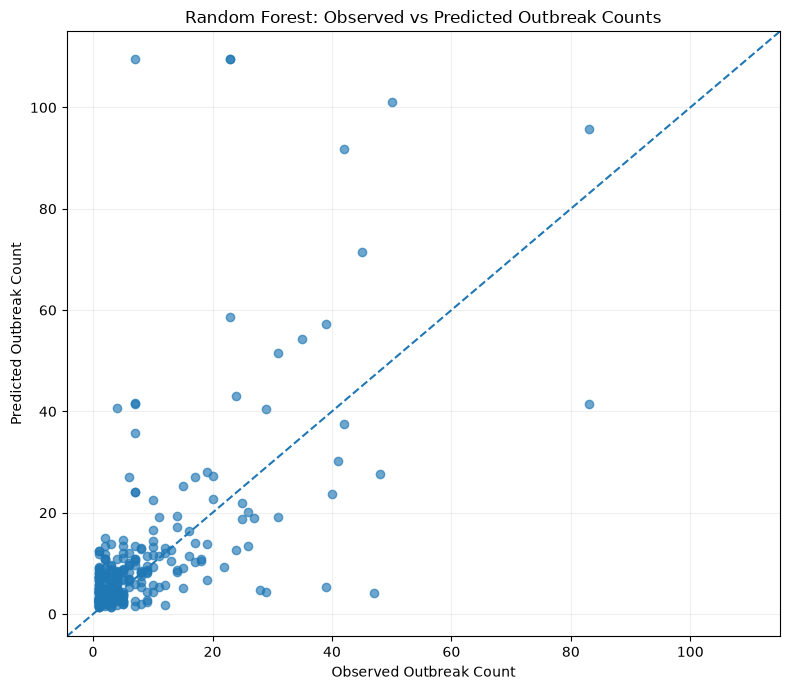

In [41]:
# ============================================================
# 7.1 ACTUAL VS PREDICTED OUT-OF-SAMPLE COUNTS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Use the previously generated OOS predictions
plot_df = oos_predictions_df.copy()

actual = plot_df[y_column]
predicted = plot_df["predicted_outbreak_count"]

# Determine plot limits
plot_min = min(actual.min(), predicted.min())
plot_max = max(actual.max(), predicted.max())

# Add a small margin
margin = (plot_max - plot_min) * 0.05
plot_min -= margin
plot_max += margin

plt.figure(figsize=(8, 7))

plt.scatter(
    actual,
    predicted,
    alpha=0.65
)

# 45-degree reference line
plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Observed Outbreak Count")
plt.ylabel("Predicted Outbreak Count")
plt.title("Random Forest: Observed vs Predicted Outbreak Counts")

plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

### 7.2 Out-of-Sample MAE Across Temporal Validation Folds

This plot shows the mean absolute error (MAE) for each chronological validation fold.

Each fold represents a future time period that was not used to train the corresponding model. The plot therefore illustrates how predictive performance varied across historical periods.

Lower MAE indicates better predictive performance.

In [44]:
# ============================================================
# 7.2 PREPARE FOLD-LEVEL MAE RESULTS
# ============================================================

print("OOS prediction columns:")
print(oos_predictions_df.columns.tolist())

print("\nOOS prediction shape:")
print(oos_predictions_df.shape)

print("\nFirst five rows:")
display(oos_predictions_df.head())

OOS prediction columns:
['temporal_period', 'target_outbreak_count', 'fold', 'predicted_outbreak_count']

OOS prediction shape:
(302, 4)

First five rows:


,temporal_period,target_outbreak_count,fold,predicted_outbreak_count
0,4044,1.0,1,1.323333
1,4044,83.0,1,95.790000
2,4044,4.0,1,1.790000
3,4044,2.0,1,11.756667
4,4044,5.0,1,3.586667


,fold,temporal_period,mae
0,1,4044.0,4.592074
1,2,4045.0,6.313946
2,3,4046.0,7.643030
3,4,4047.0,8.541212
4,5,4048.0,4.522952
5,6,4049.0,6.305556
6,7,4050.0,6.151624
7,8,4051.0,8.051813


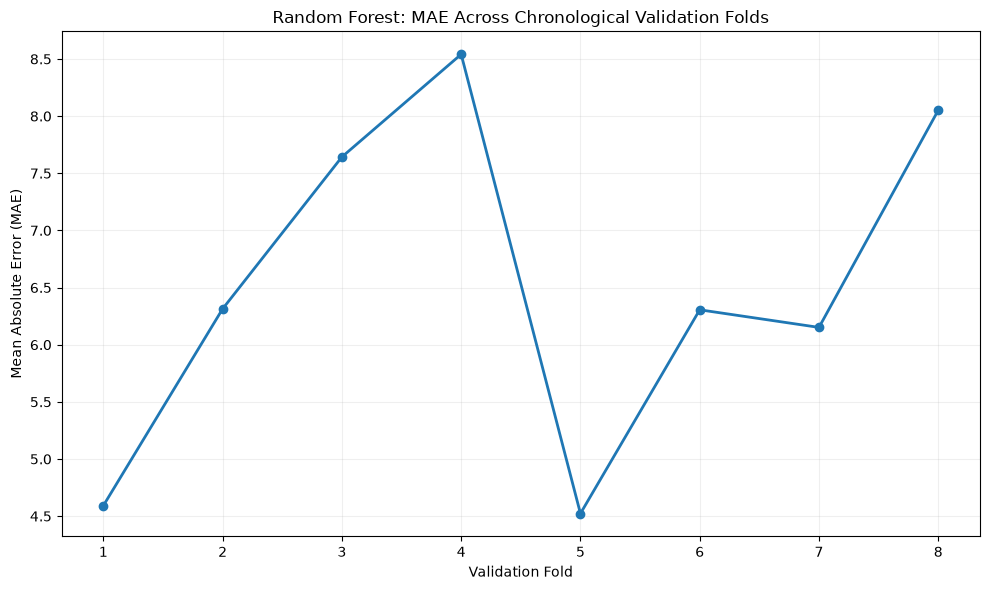

In [45]:
# ============================================================
# 7.2 OUT-OF-SAMPLE MAE ACROSS TEMPORAL VALIDATION FOLDS
# ============================================================

from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# Calculate MAE for each chronological validation fold
fold_metrics_df = (
    oos_predictions_df
    .groupby("fold")
    .apply(
        lambda group: pd.Series({
            "temporal_period": group["temporal_period"].iloc[0],
            "mae": mean_absolute_error(
                group["target_outbreak_count"],
                group["predicted_outbreak_count"]
            )
        }),
        include_groups=False
    )
    .reset_index()
)

# Display the fold-level results
display(fold_metrics_df)

# Plot MAE across chronological folds
plt.figure(figsize=(10, 6))

plt.plot(
    fold_metrics_df["fold"],
    fold_metrics_df["mae"],
    marker="o",
    linewidth=2
)

plt.xlabel("Validation Fold")
plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Random Forest: MAE Across Chronological Validation Folds")

plt.xticks(fold_metrics_df["fold"])

plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

### 7.3 Observed and Predicted Outbreak Counts Across Validation Folds

This plot compares the average observed and predicted outbreak counts for each chronological validation fold.

The comparison helps identify periods in which the model systematically over-predicted or under-predicted outbreak activity.

Because the values are aggregated by validation fold, this visualisation is intended to show temporal prediction behaviour rather than individual-observation accuracy.

,fold,temporal_period,mean_observed_outbreak_count,mean_predicted_outbreak_count
0,1,4044,7.400000,8.366593
1,2,4045,7.959184,10.120612
2,3,4046,9.818182,14.673636
3,4,4047,9.954545,13.526970
4,5,4048,8.942857,8.499524
5,6,4049,7.272727,13.578283
6,7,4050,5.692308,8.985470
7,8,4051,6.736842,12.460585


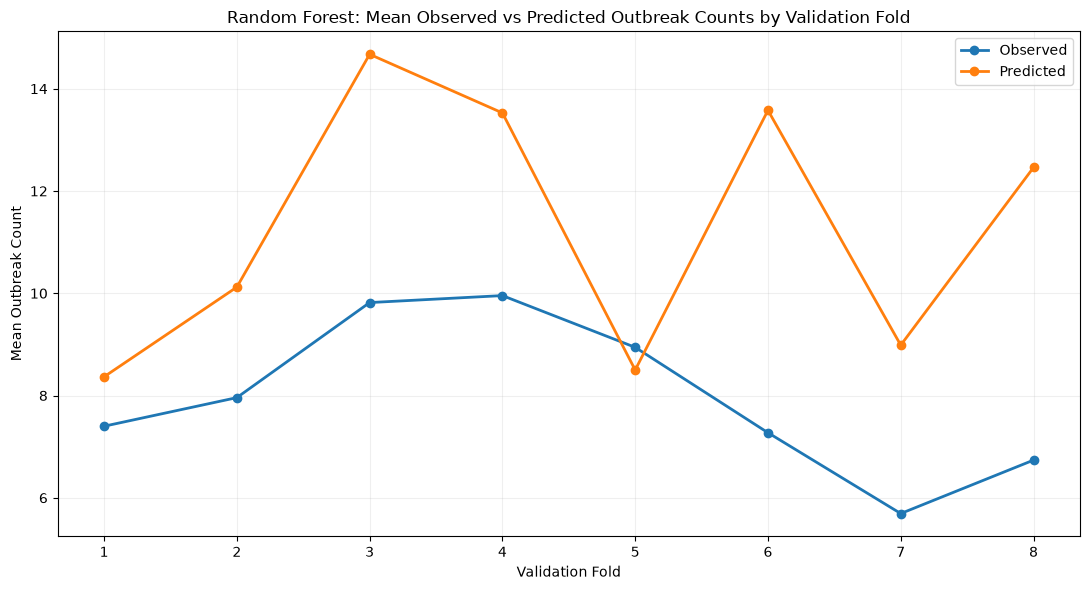

In [46]:
# ============================================================
# 7.3 OBSERVED VS PREDICTED COUNTS ACROSS VALIDATION FOLDS
# ============================================================

import matplotlib.pyplot as plt

# Calculate average observed and predicted counts by fold
temporal_performance_df = (
    oos_predictions_df
    .groupby(["fold", "temporal_period"])
    .agg(
        mean_observed_outbreak_count=(
            "target_outbreak_count",
            "mean"
        ),
        mean_predicted_outbreak_count=(
            "predicted_outbreak_count",
            "mean"
        )
    )
    .reset_index()
)

# Display the summary
display(temporal_performance_df)

# Plot observed vs predicted means
plt.figure(figsize=(11, 6))

plt.plot(
    temporal_performance_df["fold"],
    temporal_performance_df["mean_observed_outbreak_count"],
    marker="o",
    linewidth=2,
    label="Observed"
)

plt.plot(
    temporal_performance_df["fold"],
    temporal_performance_df["mean_predicted_outbreak_count"],
    marker="o",
    linewidth=2,
    label="Predicted"
)

plt.xlabel("Validation Fold")
plt.ylabel("Mean Outbreak Count")
plt.title("Random Forest: Mean Observed vs Predicted Outbreak Counts by Validation Fold")

plt.xticks(temporal_performance_df["fold"])

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

### 7.4 Distribution of Out-of-Sample Prediction Errors

This plot shows the distribution of prediction errors across all chronological out-of-sample observations.

The prediction error is defined as:

Prediction Error = Predicted Outbreak Count − Observed Outbreak Count

Positive values indicate over-prediction, while negative values indicate under-prediction.

The distribution helps assess whether the model has a systematic tendency to over-predict or under-predict outbreak counts.

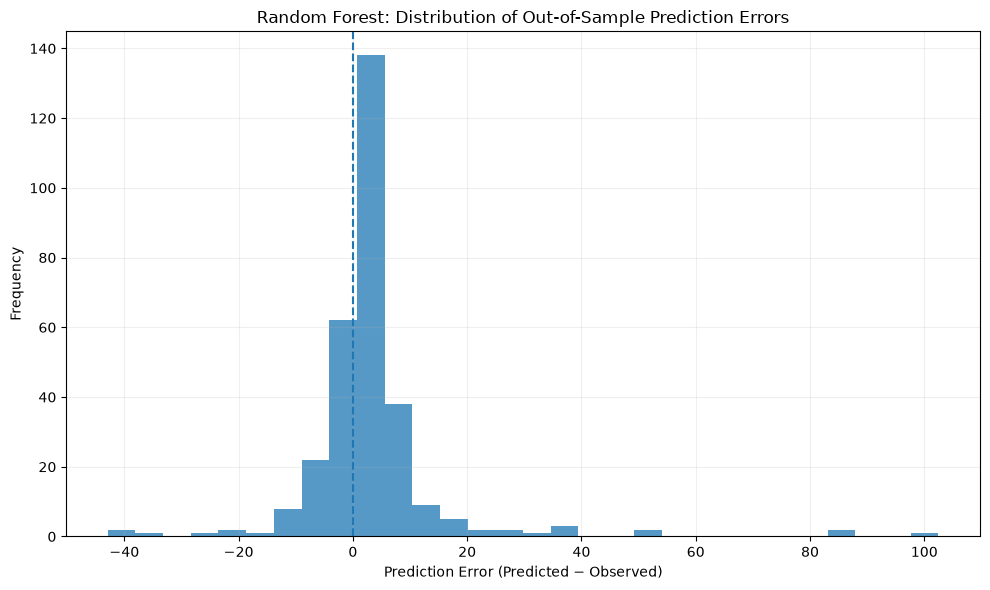

In [47]:
# ============================================================
# 7.4 DISTRIBUTION OF OUT-OF-SAMPLE PREDICTION ERRORS
# ============================================================

import matplotlib.pyplot as plt

# Calculate prediction errors
error_plot_df = oos_predictions_df.copy()

error_plot_df["prediction_error"] = (
    error_plot_df["predicted_outbreak_count"]
    - error_plot_df["target_outbreak_count"]
)

# Plot error distribution
plt.figure(figsize=(10, 6))

plt.hist(
    error_plot_df["prediction_error"],
    bins=30,
    alpha=0.75
)

# Zero-error reference line
plt.axvline(
    0,
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Prediction Error (Predicted − Observed)")
plt.ylabel("Frequency")
plt.title("Random Forest: Distribution of Out-of-Sample Prediction Errors")

plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

### 7.5 Prediction Error by Observed Outbreak Magnitude

This plot compares absolute prediction error across three observed outbreak-count categories:

- Low: 1–5 outbreaks
- Moderate: 6–20 outbreaks
- High: more than 20 outbreaks

The purpose is to assess whether predictive accuracy changes with the magnitude of observed outbreak activity.

,outbreak_magnitude,mean_absolute_error,observation_count
0,Low (1–5),3.369133,196
1,Moderate (6–20),7.136450,77
2,High (>20),25.085402,29


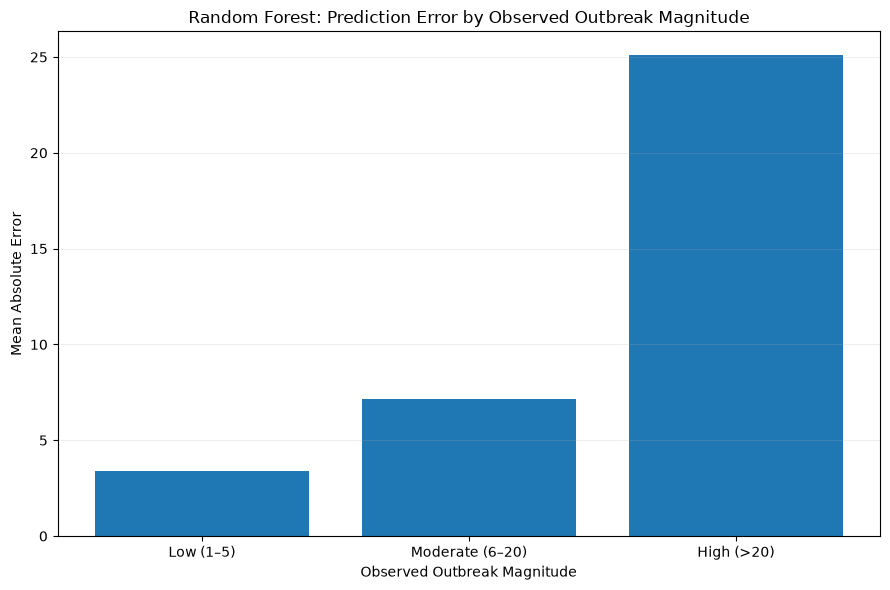

In [48]:
# ============================================================
# 7.5 ABSOLUTE ERROR BY OBSERVED OUTBREAK MAGNITUDE
# ============================================================

import matplotlib.pyplot as plt

# Create outbreak magnitude categories
magnitude_df = oos_predictions_df.copy()

magnitude_df["outbreak_magnitude"] = pd.cut(
    magnitude_df["target_outbreak_count"],
    bins=[0, 5, 20, np.inf],
    labels=["Low (1–5)", "Moderate (6–20)", "High (>20)"],
    include_lowest=True
)

# Calculate absolute prediction error
magnitude_df["absolute_error"] = (
    magnitude_df["predicted_outbreak_count"]
    - magnitude_df["target_outbreak_count"]
).abs()

# Calculate mean absolute error by magnitude category
magnitude_summary_df = (
    magnitude_df
    .groupby("outbreak_magnitude", observed=False)
    .agg(
        mean_absolute_error=("absolute_error", "mean"),
        observation_count=("absolute_error", "size")
    )
    .reset_index()
)

display(magnitude_summary_df)

# Plot
plt.figure(figsize=(9, 6))

plt.bar(
    magnitude_summary_df["outbreak_magnitude"],
    magnitude_summary_df["mean_absolute_error"]
)

plt.xlabel("Observed Outbreak Magnitude")
plt.ylabel("Mean Absolute Error")
plt.title("Random Forest: Prediction Error by Observed Outbreak Magnitude")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.show()

## 8. Final Model Evaluation Summary

This section consolidates the main out-of-sample evaluation results for the selected Random Forest model.

The primary performance estimates are based on eight chronological rolling-origin validation folds. These estimates are preferred over training-set performance because each validation observation was evaluated using a model that was fitted only on earlier observations.

The section also summarises temporal variability, prediction bias and performance across outbreak magnitudes.

In [3]:
# ============================================================
# 8.1 LOAD SAVED EVALUATION RESULTS AND BUILD FINAL SUMMARY
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error
)

# ------------------------------------------------------------
# 1. Locate project and evaluation artefacts
# ------------------------------------------------------------

project_root = Path.cwd().parent
evaluation_dir = project_root / "artifacts" / "evaluation"

oos_predictions_path = (
    evaluation_dir / "rolling_origin_oos_predictions.csv"
)

fold_metrics_path = (
    evaluation_dir / "rolling_origin_fold_metrics.csv"
)

summary_path = (
    evaluation_dir / "rolling_origin_evaluation_summary.json"
)

print("Evaluation directory:", evaluation_dir)
print("OOS predictions file exists:", oos_predictions_path.exists())
print("Fold metrics file exists:", fold_metrics_path.exists())
print("Evaluation summary file exists:", summary_path.exists())


# ------------------------------------------------------------
# 2. Load saved evaluation results
# ------------------------------------------------------------

oos_predictions_df = pd.read_csv(oos_predictions_path)
fold_metrics_df = pd.read_csv(fold_metrics_path)

print("\nOOS predictions shape:", oos_predictions_df.shape)
print("Fold metrics shape:", fold_metrics_df.shape)


# ------------------------------------------------------------
# 3. Calculate overall out-of-sample metrics
# ------------------------------------------------------------

actual = oos_predictions_df["target_outbreak_count"]
predicted = oos_predictions_df["predicted_outbreak_count"]

overall_oos_mae = mean_absolute_error(actual, predicted)

overall_oos_rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

overall_oos_median_ae = median_absolute_error(
    actual,
    predicted
)


# ------------------------------------------------------------
# 4. Calculate fold-level stability metrics
# ------------------------------------------------------------

mean_fold_mae = fold_metrics_df["mae"].mean()
std_fold_mae = fold_metrics_df["mae"].std(ddof=0)

mean_fold_rmse = fold_metrics_df["rmse"].mean()
std_fold_rmse = fold_metrics_df["rmse"].std(ddof=0)


# ------------------------------------------------------------
# 5. Calculate overall prediction bias
# ------------------------------------------------------------

signed_error = predicted - actual

mean_signed_error = signed_error.mean()


# ------------------------------------------------------------
# 6. Calculate error by outbreak magnitude
# ------------------------------------------------------------

magnitude_df = oos_predictions_df.copy()

magnitude_df["outbreak_magnitude"] = pd.cut(
    magnitude_df["target_outbreak_count"],
    bins=[0, 5, 20, np.inf],
    labels=["Low (1–5)", "Moderate (6–20)", "High (>20)"],
    include_lowest=True
)

magnitude_df["absolute_error"] = (
    magnitude_df["predicted_outbreak_count"]
    - magnitude_df["target_outbreak_count"]
).abs()

magnitude_summary_df = (
    magnitude_df
    .groupby("outbreak_magnitude", observed=False)
    .agg(
        mean_absolute_error=("absolute_error", "mean"),
        observation_count=("absolute_error", "size")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 7. Build final evaluation summary
# ------------------------------------------------------------

final_evaluation_summary = pd.DataFrame({
    "Metric": [
        "Validation method",
        "Number of validation folds",
        "Out-of-sample predictions",
        "Mean fold MAE",
        "MAE standard deviation",
        "Mean fold RMSE",
        "RMSE standard deviation",
        "Pooled out-of-sample MAE",
        "Pooled out-of-sample RMSE",
        "Pooled median absolute error",
        "Mean signed error",
        "Low-magnitude MAE (1–5)",
        "Moderate-magnitude MAE (6–20)",
        "High-magnitude MAE (>20)"
    ],
    "Value": [
        "Rolling-origin temporal validation",
        len(fold_metrics_df),
        len(oos_predictions_df),
        mean_fold_mae,
        std_fold_mae,
        mean_fold_rmse,
        std_fold_rmse,
        overall_oos_mae,
        overall_oos_rmse,
        overall_oos_median_ae,
        mean_signed_error,
        magnitude_summary_df.loc[
            magnitude_summary_df["outbreak_magnitude"] == "Low (1–5)",
            "mean_absolute_error"
        ].iloc[0],
        magnitude_summary_df.loc[
            magnitude_summary_df["outbreak_magnitude"] == "Moderate (6–20)",
            "mean_absolute_error"
        ].iloc[0],
        magnitude_summary_df.loc[
            magnitude_summary_df["outbreak_magnitude"] == "High (>20)",
            "mean_absolute_error"
        ].iloc[0]
    ]
})

display(final_evaluation_summary)

Evaluation directory: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation
OOS predictions file exists: True
Fold metrics file exists: True
Evaluation summary file exists: True

OOS predictions shape: (302, 4)
Fold metrics shape: (8, 7)


,Metric,Value
0,Validation method,Rolling-origin temporal validation
1,Number of validation folds,8
2,Out-of-sample predictions,302
3,Mean fold MAE,6.515276
4,MAE standard deviation,1.397409
5,Mean fold RMSE,11.594074
6,RMSE standard deviation,4.516479
7,Pooled out-of-sample MAE,6.415011
8,Pooled out-of-sample RMSE,13.206789
9,Pooled median absolute error,3.218333


### 8.2 Interpretation of Final Model Performance

The Random Forest model demonstrated moderate predictive performance under chronological out-of-sample evaluation.

Across eight rolling-origin validation folds, the model achieved a mean MAE of 6.515 outbreaks and a mean RMSE of 11.594 outbreaks. The pooled out-of-sample MAE was 6.415 outbreaks, while the pooled median absolute error was 3.218 outbreaks.

Performance varied across historical validation periods, indicating that predictive accuracy was not constant over time. The model also showed a positive mean signed error of 3.252 outbreaks, indicating a general tendency towards over-prediction.

Prediction error increased substantially with observed outbreak magnitude. The mean absolute error was 3.369 outbreaks for low-count observations (1–5), 7.136 for moderate counts (6–20), and 25.085 for high-count observations (>20). The high-magnitude group contained only 29 observations, so this result should be interpreted as an important limitation rather than a definitive estimate of future extreme-outbreak performance.

Overall, the results support the feasibility of using historical surveillance, temporal, geographic and climate-related variables for machine-learning-based outbreak-count forecasting. However, the model should be considered a decision-support and early-warning component rather than a replacement for epidemiological surveillance, field investigation or disease diagnosis.

### 8.3 Evaluation Artefact Verification

The formal evaluation outputs are saved as reproducible project artefacts.

These files contain the chronological fold-level metrics, individual out-of-sample predictions and consolidated evaluation summary used in this notebook.

In [4]:
# ============================================================
# 8.3 VERIFY SAVED EVALUATION ARTEFACTS
# ============================================================

from pathlib import Path

project_root = Path.cwd().parent
evaluation_dir = project_root / "artifacts" / "evaluation"

evaluation_files = [
    "rolling_origin_fold_metrics.csv",
    "rolling_origin_oos_predictions.csv",
    "rolling_origin_evaluation_summary.json",
    "random_forest_feature_importance.csv",
    "random_forest_oos_permutation_importance.csv",
]

artefact_check = pd.DataFrame({
    "file": evaluation_files,
    "exists": [
        (evaluation_dir / filename).exists()
        for filename in evaluation_files
    ]
})

display(artefact_check)

if artefact_check["exists"].all():
    print("\nEVALUATION ARTEFACT VERIFICATION: PASSED")
else:
    missing = artefact_check.loc[
        ~artefact_check["exists"],
        "file"
    ].tolist()
    raise FileNotFoundError(
        "Missing evaluation artefacts: " + ", ".join(missing)
    )

,file,exists
0,rolling_origin_fold_metrics.csv,True
1,rolling_origin_oos_predictions.csv,True
2,rolling_origin_evaluation_summary.json,True
3,random_forest_feature_importance.csv,True
4,random_forest_oos_permutation_importance.csv,True



EVALUATION ARTEFACT VERIFICATION: PASSED


## 9. Final Model and Production Artefact Verification

This section verifies that the selected model, metadata and production schema have been saved successfully and remain consistent with the final evaluation.

The verification checks the existence of the model artefact, metadata, production schema and their key configuration fields.

In [3]:
# ============================================================
# 9.1A INSPECT PRODUCTION SCHEMA STRUCTURE
# ============================================================

import json
from pathlib import Path

project_root = Path.cwd().parent
schema_path = (
    project_root
    / "artifacts"
    / "final_model"
    / "production_schema.json"
)

with open(schema_path, "r", encoding="utf-8") as f:
    production_schema = json.load(f)

print("Top-level schema keys:")
print(list(production_schema.keys()))

print("\nFeatures object type:")
print(type(production_schema["features"]).__name__)

print("\nFeatures object:")
print(json.dumps(
    production_schema["features"],
    indent=2
))

Top-level schema keys:
['schema_version', 'model', 'target', 'features', 'training', 'validation', 'input_requirements']

Features object type:
dict

Features object:
{
  "count": 27,
  "ordered_names": [
    "year",
    "semester_order",
    "is_first_semester",
    "is_second_semester",
    "semester_sin",
    "semester_cos",
    "years_since_2019",
    "year_sin",
    "year_cos",
    "has_adm1",
    "is_country_level",
    "disease_code",
    "previous_semester_outbreak_count",
    "two_semesters_prior_outbreak_count",
    "outbreak_history_mean_3",
    "outbreak_history_max_3",
    "climate_available",
    "temperature_missing",
    "dewpoint_missing",
    "precipitation_missing",
    "wind_missing",
    "climate_variable_count",
    "climate_complete",
    "temperature_c",
    "dewpoint_c",
    "semester_total_precipitation_mm",
    "semester_mean_wind_component_magnitude_ms"
  ]
}


In [4]:
# ============================================================
# 9.1B FINAL MODEL AND PRODUCTION SCHEMA VERIFICATION
# ============================================================

import json
from pathlib import Path

project_root = Path.cwd().parent

model_dir = project_root / "artifacts" / "final_model"

model_path = model_dir / "random_forest_pipeline.joblib"
metadata_path = model_dir / "model_metadata.json"
schema_path = model_dir / "production_schema.json"

# ------------------------------------------------------------
# Load artefacts
# ------------------------------------------------------------

with open(metadata_path, "r", encoding="utf-8") as f:
    final_model_metadata = json.load(f)

with open(schema_path, "r", encoding="utf-8") as f:
    production_schema = json.load(f)

# ------------------------------------------------------------
# Extract schema information
# ------------------------------------------------------------

schema_feature_count = production_schema["features"]["count"]
schema_feature_names = production_schema["features"]["ordered_names"]

metadata_feature_count = final_model_metadata["n_features"]
metadata_feature_names = final_model_metadata["features"]

# ------------------------------------------------------------
# Verification checks
# ------------------------------------------------------------

checks = {
    "model_exists": model_path.exists(),
    "metadata_exists": metadata_path.exists(),
    "schema_exists": schema_path.exists(),
    "metadata_feature_count_matches": (
        metadata_feature_count == len(metadata_feature_names)
    ),
    "schema_feature_count_matches": (
        schema_feature_count == len(schema_feature_names)
    ),
    "metadata_schema_feature_count_matches": (
        metadata_feature_count == schema_feature_count
    ),
    "metadata_schema_feature_names_match": (
        metadata_feature_names == schema_feature_names
    ),
    "model_version_matches_schema": (
        final_model_metadata["model_version"]
        == production_schema["model"]["version"]
    ),
    "target_matches": (
        final_model_metadata["target_column"]
        == production_schema["target"]["name"]
    ),
}

print("=" * 60)
print("FINAL MODEL AND PRODUCTION ARTEFACT VERIFICATION")
print("=" * 60)

print(f"\nModel directory: {model_dir}")

print("\nArtefact existence:")
print(f"  Model:    {checks['model_exists']}")
print(f"  Metadata: {checks['metadata_exists']}")
print(f"  Schema:   {checks['schema_exists']}")

print("\nFeature verification:")
print(f"  Metadata feature count: {metadata_feature_count}")
print(f"  Schema feature count:   {schema_feature_count}")
print(f"  Metadata count valid:   {checks['metadata_feature_count_matches']}")
print(f"  Schema count valid:     {checks['schema_feature_count_matches']}")
print(
    f"  Counts match:            "
    f"{checks['metadata_schema_feature_count_matches']}"
)
print(
    f"  Feature names match:     "
    f"{checks['metadata_schema_feature_names_match']}"
)

print("\nModel consistency:")
print(
    f"  Model version matches:    "
    f"{checks['model_version_matches_schema']}"
)
print(
    f"  Target column matches:    "
    f"{checks['target_matches']}"
)

print("\nOverall checks:")
for check_name, result in checks.items():
    print(f"  {check_name}: {result}")

if not all(checks.values()):
    raise ValueError(
        "FINAL MODEL AND PRODUCTION ARTEFACT VERIFICATION FAILED."
    )

print("\n" + "=" * 60)
print("FINAL MODEL AND PRODUCTION ARTEFACT VERIFICATION: PASSED")
print("=" * 60)

FINAL MODEL AND PRODUCTION ARTEFACT VERIFICATION

Model directory: c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\final_model

Artefact existence:
  Model:    True
  Metadata: True
  Schema:   True

Feature verification:
  Metadata feature count: 27
  Schema feature count:   27
  Metadata count valid:   True
  Schema count valid:     True
  Counts match:            True
  Feature names match:     True

Model consistency:
  Model version matches:    True
  Target column matches:    True

Overall checks:
  model_exists: True
  metadata_exists: True
  schema_exists: True
  metadata_feature_count_matches: True
  schema_feature_count_matches: True
  metadata_schema_feature_count_matches: True
  metadata_schema_feature_names_match: True
  model_version_matches_schema: True
  target_matches: True

FINAL MODEL AND PRODUCTION ARTEFACT VERIFICATION: PASSED


In [6]:
# ============================================================
# 9.2 RELOAD SAVED MODEL AND VERIFY PRODUCTION INFERENCE
# ============================================================

import joblib
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

project_root = Path.cwd().parent

model_dir = project_root / "artifacts" / "final_model"
evaluation_dir = project_root / "artifacts" / "evaluation"

model_path = model_dir / "random_forest_pipeline.joblib"
evaluation_dataset_path = (
    evaluation_dir / "model_evaluation_dataset.csv"
)

# ------------------------------------------------------------
# Load production schema
# ------------------------------------------------------------

schema_path = model_dir / "production_schema.json"

with open(schema_path, "r", encoding="utf-8") as f:
    production_schema = json.load(f)

schema_feature_names = (
    production_schema["features"]["ordered_names"]
)

# ------------------------------------------------------------
# Load frozen evaluation dataset
# ------------------------------------------------------------

evaluation_df = pd.read_csv(evaluation_dataset_path)

print("=" * 60)
print("SAVED MODEL RELOAD TEST")
print("=" * 60)

print(f"\nEvaluation dataset shape: {evaluation_df.shape}")
print(f"Expected feature count: {len(schema_feature_names)}")

# ------------------------------------------------------------
# Verify required production features
# ------------------------------------------------------------

missing_features = [
    feature
    for feature in schema_feature_names
    if feature not in evaluation_df.columns
]

if missing_features:
    raise ValueError(
        "Evaluation dataset is missing required features: "
        + ", ".join(missing_features)
    )

print(f"Required production features available: {len(missing_features) == 0}")

# ------------------------------------------------------------
# Load the saved production model
# ------------------------------------------------------------

reloaded_model = joblib.load(model_path)

print(
    f"\nReloaded model type: "
    f"{type(reloaded_model).__name__}"
)

# ------------------------------------------------------------
# Prepare representative production input
# ------------------------------------------------------------

production_input = evaluation_df[
    schema_feature_names
].iloc[[0]].copy()

print("\nProduction input:")
print(f"  Records:  {len(production_input)}")
print(f"  Features: {production_input.shape[1]}")

# ------------------------------------------------------------
# Generate prediction
# ------------------------------------------------------------

reloaded_prediction = reloaded_model.predict(
    production_input
)

print("\nPrediction:")
print(
    f"  Predicted outbreak count: "
    f"{reloaded_prediction[0]:.3f}"
)

# ------------------------------------------------------------
# Validate prediction
# ------------------------------------------------------------

prediction_is_finite = np.isfinite(
    reloaded_prediction
).all()

prediction_is_non_negative = (
    reloaded_prediction >= 0
).all()

prediction_count_valid = (
    len(reloaded_prediction)
    == len(production_input)
)

print("\nPrediction validation:")
print(
    f"  Prediction count valid:   "
    f"{prediction_count_valid}"
)
print(
    f"  No NaN/infinite values:    "
    f"{prediction_is_finite}"
)
print(
    f"  Non-negative prediction:   "
    f"{prediction_is_non_negative}"
)

# ------------------------------------------------------------
# Final assertion
# ------------------------------------------------------------

if not (
    prediction_count_valid
    and prediction_is_finite
    and prediction_is_non_negative
):
    raise ValueError(
        "SAVED MODEL PRODUCTION INFERENCE "
        "VERIFICATION FAILED."
    )

print("\n" + "=" * 60)
print("SAVED MODEL PRODUCTION INFERENCE: PASSED")
print("=" * 60)

SAVED MODEL RELOAD TEST

Evaluation dataset shape: (445, 28)
Expected feature count: 27
Required production features available: True

Reloaded model type: Pipeline

Production input:
  Records:  1
  Features: 27

Prediction:
  Predicted outbreak count: 5.660

Prediction validation:
  Prediction count valid:   True
  No NaN/infinite values:    True
  Non-negative prediction:   True

SAVED MODEL PRODUCTION INFERENCE: PASSED


In [7]:
# ============================================================
# 9.3 BATCH PRODUCTION INFERENCE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Prepare all production-format inputs
# ------------------------------------------------------------

production_batch = evaluation_df[
    schema_feature_names
].copy()

print("=" * 60)
print("BATCH PRODUCTION INFERENCE VERIFICATION")
print("=" * 60)

print(f"\nInput records:  {len(production_batch)}")
print(f"Input features: {production_batch.shape[1]}")

# ------------------------------------------------------------
# Generate predictions using the reloaded saved model
# ------------------------------------------------------------

batch_predictions = reloaded_model.predict(
    production_batch
)

# ------------------------------------------------------------
# Validate prediction output
# ------------------------------------------------------------

expected_records = len(production_batch)
actual_predictions = len(batch_predictions)

no_nan_or_infinite = np.isfinite(
    batch_predictions
).all()

all_non_negative = (
    batch_predictions >= 0
).all()

prediction_count_matches = (
    actual_predictions == expected_records
)

print("\nPrediction output:")
print(f"  Expected predictions:       {expected_records}")
print(f"  Actual predictions:         {actual_predictions}")
print(
    f"  Prediction count matches:   "
    f"{prediction_count_matches}"
)
print(
    f"  No NaN/infinite values:      "
    f"{no_nan_or_infinite}"
)
print(
    f"  All predictions non-negative:"
    f" {all_non_negative}"
)

# ------------------------------------------------------------
# Prediction summary
# ------------------------------------------------------------

prediction_summary = pd.Series(
    batch_predictions,
    name="predicted_outbreak_count"
).describe()

print("\nPrediction summary:")
print(prediction_summary)

# ------------------------------------------------------------
# Final assertions
# ------------------------------------------------------------

if not (
    prediction_count_matches
    and no_nan_or_infinite
    and all_non_negative
):
    raise ValueError(
        "BATCH PRODUCTION INFERENCE VERIFICATION FAILED."
    )

print("\n" + "=" * 60)
print("BATCH PRODUCTION INFERENCE VERIFICATION: PASSED")
print("=" * 60)

BATCH PRODUCTION INFERENCE VERIFICATION

Input records:  445
Input features: 27

Prediction output:
  Expected predictions:       445
  Actual predictions:         445
  Prediction count matches:   True
  No NaN/infinite values:      True
  All predictions non-negative: True

Prediction summary:
count    445.000000
mean       6.850195
std       10.458543
min        1.046667
25%        2.056667
50%        3.410000
75%        7.353333
max      130.163333
Name: predicted_outbreak_count, dtype: float64

BATCH PRODUCTION INFERENCE VERIFICATION: PASSED


In [8]:
# ============================================================
# 9.4 FINAL PRODUCTION INFERENCE FUNCTION VERIFICATION
# ============================================================

# ------------------------------------------------------------
# Define the production inference function
# ------------------------------------------------------------

def predict_outbreak_count(input_data, model=reloaded_model):
    """
    Generate poultry disease outbreak-count predictions
    from production-format input data.

    Parameters
    ----------
    input_data : pandas.DataFrame
        DataFrame containing the required 27 model features.

    model : fitted model pipeline
        Saved production model.

    Returns
    -------
    pandas.DataFrame
        DataFrame containing predicted outbreak counts.
    """

    if not isinstance(input_data, pd.DataFrame):
        raise TypeError(
            "input_data must be a pandas DataFrame."
        )

    missing_features = [
        feature
        for feature in schema_feature_names
        if feature not in input_data.columns
    ]

    if missing_features:
        raise ValueError(
            "Missing required model features: "
            + ", ".join(missing_features)
        )

    X_input = input_data[
        schema_feature_names
    ].copy()

    predictions = model.predict(X_input)

    if not np.isfinite(predictions).all():
        raise ValueError(
            "Model generated NaN or infinite predictions."
        )

    if (predictions < 0).any():
        raise ValueError(
            "Model generated negative outbreak-count predictions."
        )

    return pd.DataFrame(
        {
            "predicted_outbreak_count": predictions
        }
    )


# ------------------------------------------------------------
# Test the production function with the full dataset
# ------------------------------------------------------------

production_predictions = predict_outbreak_count(
    production_batch
)

print("=" * 60)
print("PRODUCTION INFERENCE FUNCTION VERIFICATION")
print("=" * 60)

print("\nFunction output:")
print(f"  Input records:       {len(production_batch)}")
print(f"  Output records:      {len(production_predictions)}")
print(f"  Output columns:      {list(production_predictions.columns)}")

# ------------------------------------------------------------
# Validate output
# ------------------------------------------------------------

output_count_matches = (
    len(production_predictions)
    == len(production_batch)
)

expected_output_column = (
    list(production_predictions.columns)
    == ["predicted_outbreak_count"]
)

predictions_finite = np.isfinite(
    production_predictions["predicted_outbreak_count"]
).all()

predictions_non_negative = (
    production_predictions["predicted_outbreak_count"]
    >= 0
).all()

print("\nValidation:")
print(
    f"  Output record count matches: "
    f"{output_count_matches}"
)
print(
    f"  Output column is correct:    "
    f"{expected_output_column}"
)
print(
    f"  Predictions are finite:       "
    f"{predictions_finite}"
)
print(
    f"  Predictions non-negative:     "
    f"{predictions_non_negative}"
)

# ------------------------------------------------------------
# Display sample predictions
# ------------------------------------------------------------

print("\nSample predictions:")
print(
    production_predictions.head(5).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# Final assertion
# ------------------------------------------------------------

if not (
    output_count_matches
    and expected_output_column
    and predictions_finite
    and predictions_non_negative
):
    raise ValueError(
        "PRODUCTION INFERENCE FUNCTION "
        "VERIFICATION FAILED."
    )

print("\n" + "=" * 60)
print("PRODUCTION INFERENCE FUNCTION: PASSED")
print("=" * 60)

PRODUCTION INFERENCE FUNCTION VERIFICATION

Function output:
  Input records:       445
  Output records:      445
  Output columns:      ['predicted_outbreak_count']

Validation:
  Output record count matches: True
  Output column is correct:    True
  Predictions are finite:       True
  Predictions non-negative:     True

Sample predictions:
 predicted_outbreak_count
                 5.660000
                 2.423333
                 1.996667
                 4.926667
                 2.683333

PRODUCTION INFERENCE FUNCTION: PASSED


In [10]:
# ============================================================
# 10.1 INSPECT SAVED EVALUATION SUMMARY STRUCTURE
# ============================================================

import json
from pathlib import Path

project_root = Path.cwd().parent

evaluation_summary_path = (
    project_root
    / "artifacts"
    / "evaluation"
    / "rolling_origin_evaluation_summary.json"
)

with open(evaluation_summary_path, "r", encoding="utf-8") as f:
    evaluation_summary = json.load(f)

print("=" * 60)
print("SAVED EVALUATION SUMMARY STRUCTURE")
print("=" * 60)

print("\nTop-level keys:")
for key in evaluation_summary.keys():
    print(f"  - {key}")

print("\nComplete evaluation summary:")
print(json.dumps(
    evaluation_summary,
    indent=2
))

SAVED EVALUATION SUMMARY STRUCTURE

Top-level keys:
  - evaluation_method
  - validation_folds
  - out_of_sample_predictions
  - validation_periods
  - mean_fold_mae
  - std_fold_mae
  - mean_fold_rmse
  - std_fold_rmse
  - mean_fold_median_absolute_error
  - pooled_mae
  - pooled_rmse
  - pooled_median_absolute_error

Complete evaluation summary:
{
  "evaluation_method": "rolling_origin_temporal_validation",
  "validation_folds": 8,
  "out_of_sample_predictions": 302,
  "validation_periods": [
    4044,
    4045,
    4046,
    4047,
    4048,
    4049,
    4050,
    4051
  ],
  "mean_fold_mae": 6.515275851272092,
  "std_fold_mae": 1.4938928511753018,
  "mean_fold_rmse": 11.594073626101732,
  "std_fold_rmse": 4.828319221470369,
  "mean_fold_median_absolute_error": 3.337083333333333,
  "pooled_mae": 6.415011037527593,
  "pooled_rmse": 13.20678935203263,
  "pooled_median_absolute_error": 3.2183333333333333
}


In [11]:
# ============================================================
# 10.2 FINAL PERFORMANCE METRIC CONSISTENCY CHECK
# ============================================================

import json
from pathlib import Path

project_root = Path.cwd().parent

evaluation_dir = project_root / "artifacts" / "evaluation"
final_model_dir = project_root / "artifacts" / "final_model"

# ------------------------------------------------------------
# Load saved evaluation summary
# ------------------------------------------------------------

evaluation_summary_path = (
    evaluation_dir / "rolling_origin_evaluation_summary.json"
)

with open(evaluation_summary_path, "r", encoding="utf-8") as f:
    evaluation_summary = json.load(f)

# ------------------------------------------------------------
# Load saved model metadata
# ------------------------------------------------------------

metadata_path = (
    final_model_dir / "model_metadata.json"
)

with open(metadata_path, "r", encoding="utf-8") as f:
    model_metadata = json.load(f)

# ------------------------------------------------------------
# Extract comparable metrics
# ------------------------------------------------------------

evaluation_mean_mae = evaluation_summary["mean_fold_mae"]
evaluation_mean_rmse = evaluation_summary["mean_fold_rmse"]

metadata_mean_mae = (
    model_metadata["validation"]["mean_fold_mae"]
)

metadata_mean_rmse = (
    model_metadata["validation"]["mean_fold_rmse"]
)

# ------------------------------------------------------------
# Calculate differences
# ------------------------------------------------------------

mae_difference = (
    evaluation_mean_mae - metadata_mean_mae
)

rmse_difference = (
    evaluation_mean_rmse - metadata_mean_rmse
)

# ------------------------------------------------------------
# Display comparison
# ------------------------------------------------------------

print("=" * 60)
print("FINAL PERFORMANCE METRIC CONSISTENCY CHECK")
print("=" * 60)

print("\nSaved evaluation summary:")
print(
    f"  Mean fold MAE:  "
    f"{evaluation_mean_mae:.6f}"
)
print(
    f"  Mean fold RMSE: "
    f"{evaluation_mean_rmse:.6f}"
)
print(
    f"  Pooled OOS MAE: "
    f"{evaluation_summary['pooled_mae']:.6f}"
)
print(
    f"  Pooled OOS RMSE:"
    f" {evaluation_summary['pooled_rmse']:.6f}"
)

print("\nSaved model metadata:")
print(
    f"  Mean fold MAE:  "
    f"{metadata_mean_mae:.6f}"
)
print(
    f"  Mean fold RMSE: "
    f"{metadata_mean_rmse:.6f}"
)

print("\nDifferences:")
print(
    f"  MAE difference:  "
    f"{mae_difference:.6f}"
)
print(
    f"  RMSE difference: "
    f"{rmse_difference:.6f}"
)

print("\nEvaluation periods:")
print(
    f"  {evaluation_summary['validation_periods']}"
)

print(
    f"\nOut-of-sample predictions: "
    f"{evaluation_summary['out_of_sample_predictions']}"
)

print("\n" + "=" * 60)
print("CONSISTENCY CHECK COMPLETE")
print("=" * 60)

FINAL PERFORMANCE METRIC CONSISTENCY CHECK

Saved evaluation summary:
  Mean fold MAE:  6.515276
  Mean fold RMSE: 11.594074
  Pooled OOS MAE: 6.415011
  Pooled OOS RMSE: 13.206789

Saved model metadata:
  Mean fold MAE:  6.533000
  Mean fold RMSE: 11.603000

Differences:
  MAE difference:  -0.017724
  RMSE difference: -0.008926

Evaluation periods:
  [4044, 4045, 4046, 4047, 4048, 4049, 4050, 4051]

Out-of-sample predictions: 302

CONSISTENCY CHECK COMPLETE


In [12]:
# ============================================================
# 10.3 INSPECT FINAL MODEL METADATA VALIDATION SECTION
# ============================================================

import json
from pathlib import Path

project_root = Path.cwd().parent

metadata_path = (
    project_root
    / "artifacts"
    / "final_model"
    / "model_metadata.json"
)

with open(metadata_path, "r", encoding="utf-8") as f:
    model_metadata = json.load(f)

print("=" * 60)
print("FINAL MODEL METADATA — VALIDATION SECTION")
print("=" * 60)

print(
    json.dumps(
        model_metadata["validation"],
        indent=2
    )
)

FINAL MODEL METADATA — VALIDATION SECTION
{
  "method": "rolling_origin_temporal_validation",
  "folds": 8,
  "mean_fold_mae": 6.533,
  "std_fold_mae": 1.661,
  "mean_fold_rmse": 11.603,
  "std_fold_rmse": 5.042,
  "mean_fold_median_absolute_error": 3.241
}


In [13]:
# ============================================================
# 10.4 SYNCHRONISE FINAL MODEL METADATA WITH FORMAL EVALUATION
# ============================================================

import json
from pathlib import Path

project_root = Path.cwd().parent

metadata_path = (
    project_root
    / "artifacts"
    / "final_model"
    / "model_metadata.json"
)

evaluation_summary_path = (
    project_root
    / "artifacts"
    / "evaluation"
    / "rolling_origin_evaluation_summary.json"
)

# ------------------------------------------------------------
# Load both persisted records
# ------------------------------------------------------------

with open(metadata_path, "r", encoding="utf-8") as f:
    model_metadata = json.load(f)

with open(evaluation_summary_path, "r", encoding="utf-8") as f:
    evaluation_summary = json.load(f)

# ------------------------------------------------------------
# Preserve the existing metadata structure and update only
# the validation metrics with the authoritative evaluation.
# ------------------------------------------------------------

model_metadata["validation"] = {
    "method": evaluation_summary["evaluation_method"],
    "folds": evaluation_summary["validation_folds"],
    "mean_fold_mae": evaluation_summary["mean_fold_mae"],
    "std_fold_mae": evaluation_summary["std_fold_mae"],
    "mean_fold_rmse": evaluation_summary["mean_fold_rmse"],
    "std_fold_rmse": evaluation_summary["std_fold_rmse"],
    "mean_fold_median_absolute_error":
        evaluation_summary["mean_fold_median_absolute_error"],
    "pooled_mae": evaluation_summary["pooled_mae"],
    "pooled_rmse": evaluation_summary["pooled_rmse"],
    "pooled_median_absolute_error":
        evaluation_summary["pooled_median_absolute_error"],
    "out_of_sample_predictions":
        evaluation_summary["out_of_sample_predictions"],
    "validation_periods":
        evaluation_summary["validation_periods"],
}

# ------------------------------------------------------------
# Save updated metadata
# ------------------------------------------------------------

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(
        model_metadata,
        f,
        indent=2
    )

# ------------------------------------------------------------
# Reload and verify
# ------------------------------------------------------------

with open(metadata_path, "r", encoding="utf-8") as f:
    verified_metadata = json.load(f)

verified_validation = verified_metadata["validation"]

print("=" * 60)
print("FINAL MODEL METADATA SYNCHRONISATION")
print("=" * 60)

print("\nUpdated validation metadata:")

for key, value in verified_validation.items():
    print(f"  {key}: {value}")

# ------------------------------------------------------------
# Consistency checks
# ------------------------------------------------------------

checks = {
    "method_matches": (
        verified_validation["method"]
        == evaluation_summary["evaluation_method"]
    ),
    "folds_match": (
        verified_validation["folds"]
        == evaluation_summary["validation_folds"]
    ),
    "mean_mae_matches": (
        verified_validation["mean_fold_mae"]
        == evaluation_summary["mean_fold_mae"]
    ),
    "std_mae_matches": (
        verified_validation["std_fold_mae"]
        == evaluation_summary["std_fold_mae"]
    ),
    "mean_rmse_matches": (
        verified_validation["mean_fold_rmse"]
        == evaluation_summary["mean_fold_rmse"]
    ),
    "std_rmse_matches": (
        verified_validation["std_fold_rmse"]
        == evaluation_summary["std_fold_rmse"]
    ),
    "median_ae_matches": (
        verified_validation["mean_fold_median_absolute_error"]
        == evaluation_summary[
            "mean_fold_median_absolute_error"
        ]
    ),
    "pooled_mae_matches": (
        verified_validation["pooled_mae"]
        == evaluation_summary["pooled_mae"]
    ),
    "pooled_rmse_matches": (
        verified_validation["pooled_rmse"]
        == evaluation_summary["pooled_rmse"]
    ),
    "pooled_median_ae_matches": (
        verified_validation[
            "pooled_median_absolute_error"
        ]
        == evaluation_summary[
            "pooled_median_absolute_error"
        ]
    ),
    "oos_prediction_count_matches": (
        verified_validation["out_of_sample_predictions"]
        == evaluation_summary["out_of_sample_predictions"]
    ),
    "validation_periods_match": (
        verified_validation["validation_periods"]
        == evaluation_summary["validation_periods"]
    ),
}

print("\nConsistency checks:")

for check_name, result in checks.items():
    print(f"  {check_name}: {result}")

if not all(checks.values()):
    raise ValueError(
        "MODEL METADATA SYNCHRONISATION FAILED."
    )

print("\n" + "=" * 60)
print("MODEL METADATA SYNCHRONISATION: PASSED")
print("=" * 60)

FINAL MODEL METADATA SYNCHRONISATION

Updated validation metadata:
  method: rolling_origin_temporal_validation
  folds: 8
  mean_fold_mae: 6.515275851272092
  std_fold_mae: 1.4938928511753018
  mean_fold_rmse: 11.594073626101732
  std_fold_rmse: 4.828319221470369
  mean_fold_median_absolute_error: 3.337083333333333
  pooled_mae: 6.415011037527593
  pooled_rmse: 13.20678935203263
  pooled_median_absolute_error: 3.2183333333333333
  out_of_sample_predictions: 302
  validation_periods: [4044, 4045, 4046, 4047, 4048, 4049, 4050, 4051]

Consistency checks:
  method_matches: True
  folds_match: True
  mean_mae_matches: True
  std_mae_matches: True
  mean_rmse_matches: True
  std_rmse_matches: True
  median_ae_matches: True
  pooled_mae_matches: True
  pooled_rmse_matches: True
  pooled_median_ae_matches: True
  oos_prediction_count_matches: True
  validation_periods_match: True

MODEL METADATA SYNCHRONISATION: PASSED


In [14]:
# ============================================================
# 10.5 FINAL PROJECT ARTEFACT INTEGRITY CHECK
# ============================================================

import json
import joblib
from pathlib import Path

project_root = Path.cwd().parent

final_model_dir = (
    project_root / "artifacts" / "final_model"
)

evaluation_dir = (
    project_root / "artifacts" / "evaluation"
)

# ------------------------------------------------------------
# Required artefacts
# ------------------------------------------------------------

required_artefacts = {
    "final_model": (
        final_model_dir
        / "random_forest_pipeline.joblib"
    ),
    "model_metadata": (
        final_model_dir
        / "model_metadata.json"
    ),
    "production_schema": (
        final_model_dir
        / "production_schema.json"
    ),
    "fold_metrics": (
        evaluation_dir
        / "rolling_origin_fold_metrics.csv"
    ),
    "oos_predictions": (
        evaluation_dir
        / "rolling_origin_oos_predictions.csv"
    ),
    "evaluation_summary": (
        evaluation_dir
        / "rolling_origin_evaluation_summary.json"
    ),
    "feature_importance": (
        evaluation_dir
        / "random_forest_feature_importance.csv"
    ),
    "oos_permutation_importance": (
        evaluation_dir
        / "random_forest_oos_permutation_importance.csv"
    ),
}

print("=" * 60)
print("FINAL PROJECT ARTEFACT INTEGRITY CHECK")
print("=" * 60)

# ------------------------------------------------------------
# Check existence
# ------------------------------------------------------------

existence_checks = {}

print("\nRequired artefacts:")

for name, path in required_artefacts.items():
    exists = path.exists()
    existence_checks[name] = exists
    print(f"  {name}: {exists}")

# ------------------------------------------------------------
# Load critical artefacts
# ------------------------------------------------------------

model = joblib.load(
    required_artefacts["final_model"]
)

with open(
    required_artefacts["model_metadata"],
    "r",
    encoding="utf-8"
) as f:
    metadata = json.load(f)

with open(
    required_artefacts["production_schema"],
    "r",
    encoding="utf-8"
) as f:
    schema = json.load(f)

with open(
    required_artefacts["evaluation_summary"],
    "r",
    encoding="utf-8"
) as f:
    evaluation_summary = json.load(f)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

integrity_checks = {
    "model_is_pipeline": (
        type(model).__name__ == "Pipeline"
    ),
    "feature_count_is_27": (
        metadata["n_features"] == 27
    ),
    "schema_feature_count_is_27": (
        schema["features"]["count"] == 27
    ),
    "metadata_schema_features_match": (
        metadata["features"]
        == schema["features"]["ordered_names"]
    ),
    "metadata_validation_matches_evaluation": (
        metadata["validation"]["mean_fold_mae"]
        == evaluation_summary["mean_fold_mae"]
        and
        metadata["validation"]["mean_fold_rmse"]
        == evaluation_summary["mean_fold_rmse"]
        and
        metadata["validation"]["pooled_mae"]
        == evaluation_summary["pooled_mae"]
        and
        metadata["validation"]["pooled_rmse"]
        == evaluation_summary["pooled_rmse"]
    ),
    "validation_fold_count_is_8": (
        evaluation_summary["validation_folds"] == 8
    ),
    "oos_prediction_count_is_302": (
        evaluation_summary["out_of_sample_predictions"] == 302
    ),
}

print("\nIntegrity checks:")

for name, result in integrity_checks.items():
    print(f"  {name}: {result}")

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

all_checks = (
    all(existence_checks.values())
    and all(integrity_checks.values())
)

if not all_checks:
    raise ValueError(
        "FINAL PROJECT ARTEFACT INTEGRITY CHECK FAILED."
    )

print("\n" + "=" * 60)
print("FINAL PROJECT ARTEFACT INTEGRITY CHECK: PASSED")
print("=" * 60)

FINAL PROJECT ARTEFACT INTEGRITY CHECK

Required artefacts:
  final_model: True
  model_metadata: True
  production_schema: True
  fold_metrics: True
  oos_predictions: True
  evaluation_summary: True
  feature_importance: True
  oos_permutation_importance: True

Integrity checks:
  model_is_pipeline: True
  feature_count_is_27: True
  schema_feature_count_is_27: True
  metadata_schema_features_match: True
  metadata_validation_matches_evaluation: True
  validation_fold_count_is_8: True
  oos_prediction_count_is_302: True

FINAL PROJECT ARTEFACT INTEGRITY CHECK: PASSED
